# Phần 5: Tương quan giữa các môn

**2023 — CT2006** so với **2025 — CT2018**. Dataset 2025 chỉ gồm CT2018 theo xác nhận của người dùng. Điểm thiếu không được điền; điểm 0 giữ nguyên.

Notebook đọc đầu ra đã kiểm chứng. Đặt `RERUN=True` để chạy lại bằng `--rerun`. Mỗi lần chạy lại thực hiện cả hai phần để metadata thống nhất.

In [1]:
from pathlib import Path
import sys, subprocess, json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/score_data.py").exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
RERUN = False
if RERUN:
    subprocess.run([sys.executable, "-m", "src.run_parts3_5", "--rerun"], cwd=ROOT, check=True)
from src.run_parts3_5 import validate_outputs
print(validate_outputs(ROOT))
metadata = json.loads((ROOT / "outputs/parts3_5_run.json").read_text(encoding="utf-8"))
display(pd.DataFrame(metadata["inputs"])[["cohort", "rows", "rows_with_any_score", "sha256"]])

{'checked_csv_files': 13, 'cohorts': ['2023 — CT2006', '2025 — CT2018'], 'status': 'coverage, counts, ties, stored totals and symmetric correlations verified'}


,cohort,rows,rows_with_any_score,sha256
0,2023 — CT2006,1022060,1017584,cdf22a6b45f8e23b522beb1c521782e36486cac39d3fb6...
1,2025 — CT2018,1131136,1130984,0db00925d51bcb14dfb6c92efeee9926524aba89382889...


## pairwise_correlations.csv

In [2]:
display(pd.read_csv(ROOT / "outputs/correlations/pairwise_correlations.csv"))

,year,cohort,subject_x,subject_y,n_pair,pearson_r,spearman_rho,status
0,2023,2023 — CT2006,math,math,1003373,1.000000,1.000000,ok
1,2023,2023 — CT2006,math,literature,994167,0.458616,0.415123,ok
2,2023,2023 — CT2006,math,english,875554,0.591779,0.606839,ok
3,2023,2023 — CT2006,math,physics,327173,0.567558,0.555865,ok
4,2023,2023 — CT2006,math,chemistry,328097,0.463384,0.444897,ok
...,...,...,...,...,...,...,...,...
123,2025,2025 — CT2018,geography,physics,5194,0.491087,0.481662,ok
124,2025,2025 — CT2018,geography,chemistry,1363,0.594069,0.596414,ok
125,2025,2025 — CT2018,geography,biology,1442,0.640760,0.634524,ok
126,2025,2025 — CT2018,geography,history,297403,0.758875,0.762891,ok


## correlation_deltas.csv

In [3]:
display(pd.read_csv(ROOT / "outputs/correlations/correlation_deltas.csv"))

,subject_x,subject_y,cohort_from,cohort_to,year_from,year_to,n_pair_from,n_pair_to,pearson_r_from,pearson_r_to,spearman_rho_from,spearman_rho_to,delta_pearson_r,delta_spearman_rho,status_from,status_to
0,math,literature,2023 — CT2006,2025 — CT2018,2023,2025,994167,1121925,0.458616,0.382674,0.415123,0.384679,-0.075942,-0.030444,ok,ok
1,math,english,2023 — CT2006,2025 — CT2018,2023,2025,875554,351679,0.591779,0.496774,0.606839,0.496488,-0.095005,-0.110352,ok,ok
2,math,physics,2023 — CT2006,2025 — CT2018,2023,2025,327173,347591,0.567558,0.709381,0.555865,0.708073,0.141823,0.152208,ok,ok
3,math,chemistry,2023 — CT2006,2025 — CT2018,2023,2025,328097,240129,0.463384,0.728263,0.444897,0.720436,0.264879,0.275539,ok,ok
4,math,biology,2023 — CT2006,2025 — CT2018,2023,2025,324596,69894,0.312968,0.739196,0.294144,0.731508,0.426228,0.437364,ok,ok
5,math,history,2023 — CT2006,2025 — CT2018,2023,2025,669833,476793,0.468736,0.517955,0.463853,0.523607,0.049219,0.059755,ok,ok
6,math,geography,2023 — CT2006,2025 — CT2018,2023,2025,668492,472060,0.445639,0.554460,0.426376,0.560829,0.108821,0.134452,ok,ok
7,literature,english,2023 — CT2006,2025 — CT2018,2023,2025,873568,350821,0.366165,0.183929,0.368466,0.198002,-0.182236,-0.170464,ok,ok
8,literature,physics,2023 — CT2006,2025 — CT2018,2023,2025,320531,345017,0.180650,0.210588,0.172863,0.198648,0.029938,0.025785,ok,ok
9,literature,chemistry,2023 — CT2006,2025 — CT2018,2023,2025,320474,237065,0.200267,0.206952,0.187767,0.203345,0.006685,0.015579,ok,ok


## group_sensitivity.csv

In [4]:
display(pd.read_csv(ROOT / "outputs/correlations/group_sensitivity.csv"))

,combination,year,cohort,subject_x,subject_y,n_pair,pearson_r,spearman_rho,status
0,A00,2023,2023 — CT2006,math,physics,325902,0.566780,0.555352,ok
1,A00,2023,2023 — CT2006,math,chemistry,325902,0.461816,0.443472,ok
2,A00,2023,2023 — CT2006,physics,chemistry,325902,0.377815,0.373722,ok
3,A01,2023,2023 — CT2006,math,physics,314412,0.567399,0.555726,ok
4,A01,2023,2023 — CT2006,math,english,314412,0.389794,0.378334,ok
5,A01,2023,2023 — CT2006,physics,english,314412,0.317712,0.312689,ok
6,B00,2023,2023 — CT2006,math,chemistry,324554,0.459848,0.443296,ok
7,B00,2023,2023 — CT2006,math,biology,324554,0.312884,0.294098,ok
8,B00,2023,2023 — CT2006,chemistry,biology,324554,0.406690,0.390212,ok
9,C00,2023,2023 — CT2006,literature,history,681723,0.452937,0.440529,ok


## high_score_concordance.csv

In [5]:
display(pd.read_csv(ROOT / "outputs/correlations/high_score_concordance.csv"))

,year,cohort,subject_x,subject_y,n_pair,p80_x,p80_y,n_x_high,n_y_high,n_both_high,n_x_at_threshold,n_y_at_threshold,x_high_probability,baseline_probability,conditional_probability,status
0,2023,2023 — CT2006,math,physics,327173,8.2,8.00,80963,69746,38154,27044,19843,0.247462,0.213178,0.471252,ok
1,2023,2023 — CT2006,chemistry,biology,324571,8.0,7.50,73667,67398,28989,21979,18484,0.226967,0.207653,0.393514,ok
2,2023,2023 — CT2006,literature,history,683263,8.0,7.50,173525,144816,69596,43328,29284,0.253965,0.211948,0.401072,ok
3,2025,2025 — CT2018,math,physics,347591,7.5,8.50,70919,70743,42755,15475,15952,0.204030,0.203524,0.602871,ok
4,2025,2025 — CT2018,chemistry,biology,44964,8.0,7.75,10293,9201,6216,1474,1717,0.228916,0.204630,0.603906,ok
5,2025,2025 — CT2018,literature,history,481156,8.0,8.00,119627,110826,55438,33812,21633,0.248624,0.230333,0.463424,ok


## Biểu đồ và báo cáo
Hình được đọc từ cùng bộ kết quả với các bảng trên.

Có 12 hình; danh sách đầy đủ:


,figure
0,outputs\correlations\figures\hexbin_chemistry_...
1,outputs\correlations\figures\hexbin_history_ge...
2,outputs\correlations\figures\hexbin_math_engli...
3,outputs\correlations\figures\hexbin_math_physi...
4,outputs\correlations\figures\hexbin_physics_ch...
5,outputs\correlations\figures\high_score_concor...
6,outputs\correlations\figures\n_pair_2023.png
7,outputs\correlations\figures\n_pair_2025.png
8,outputs\correlations\figures\pearson_r_2023.png
9,outputs\correlations\figures\pearson_r_2025.png


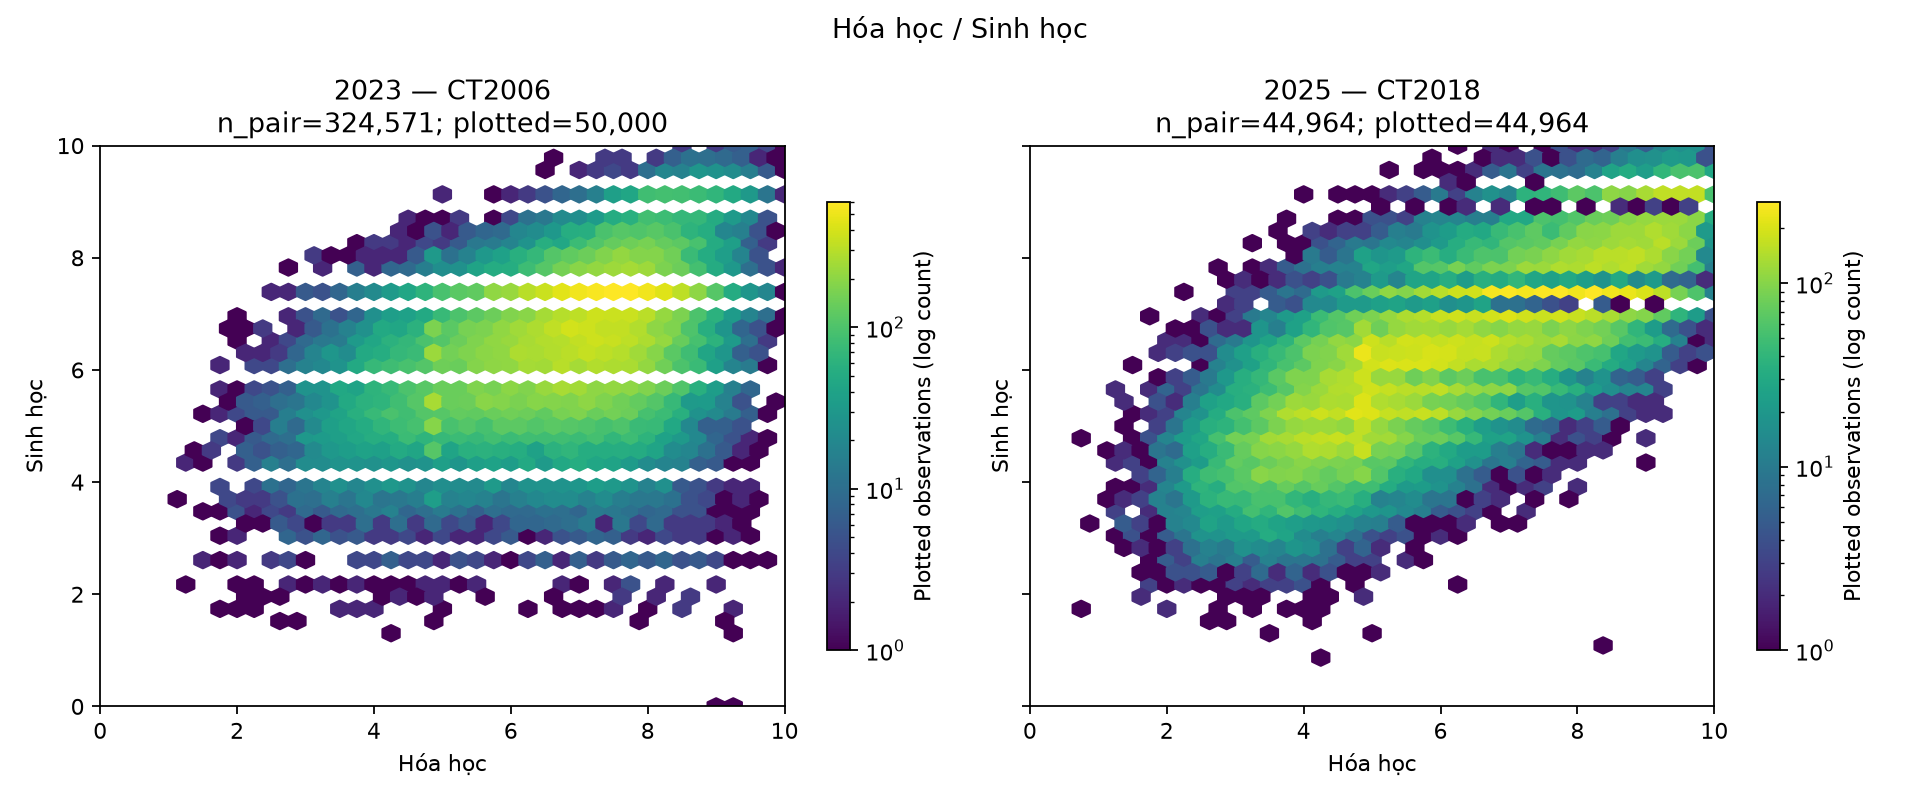

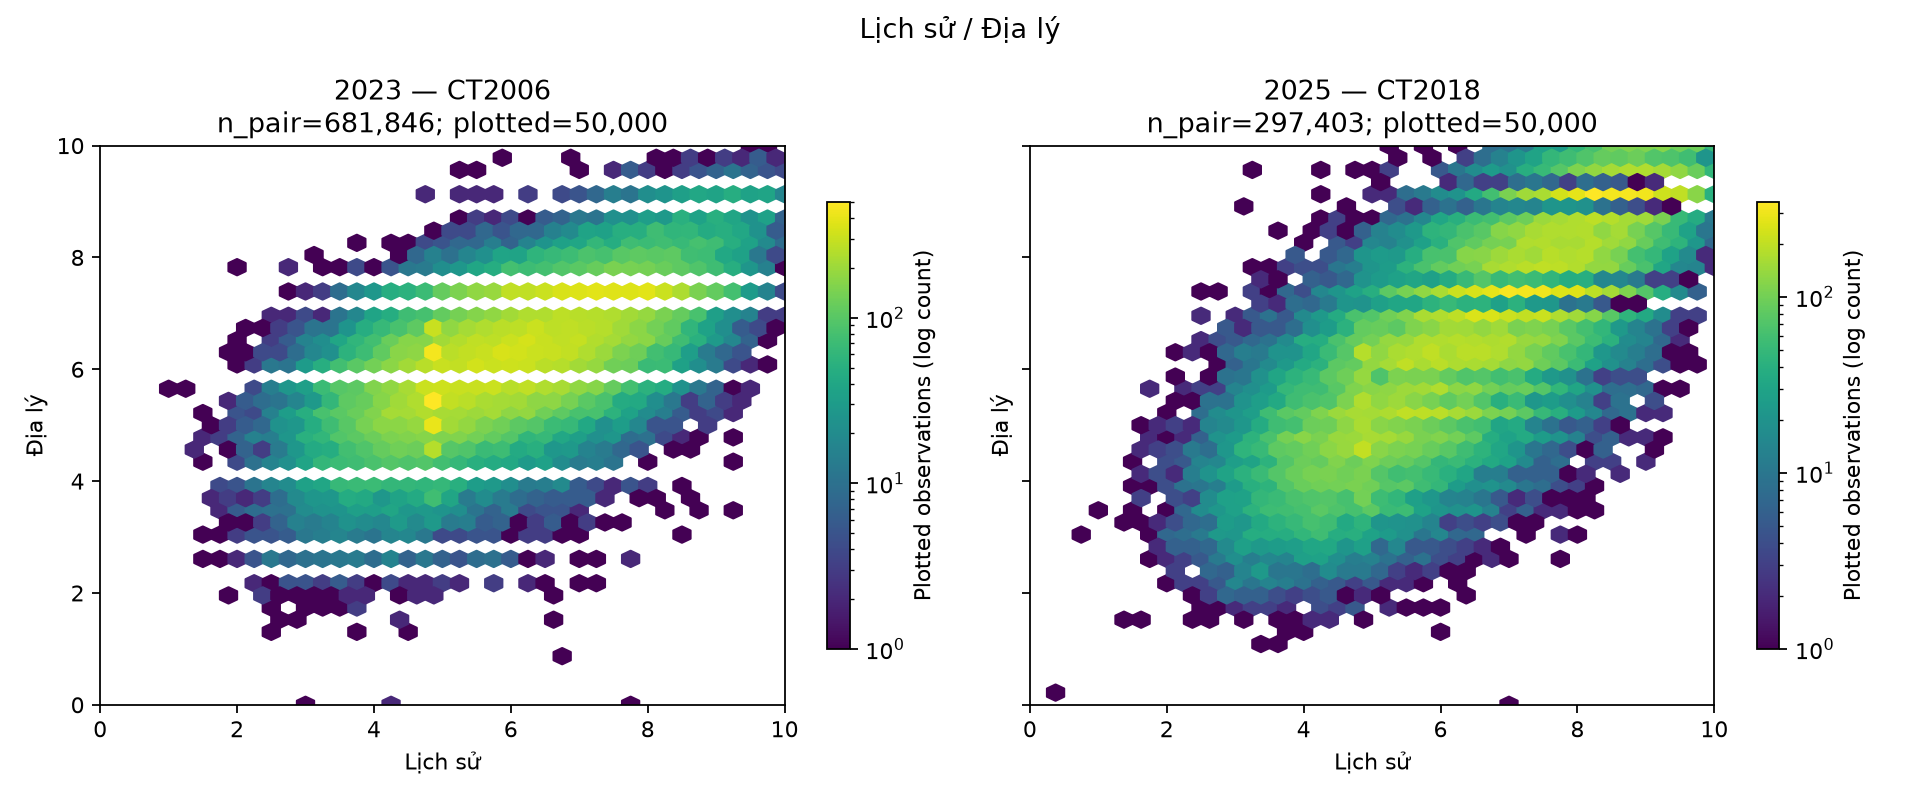

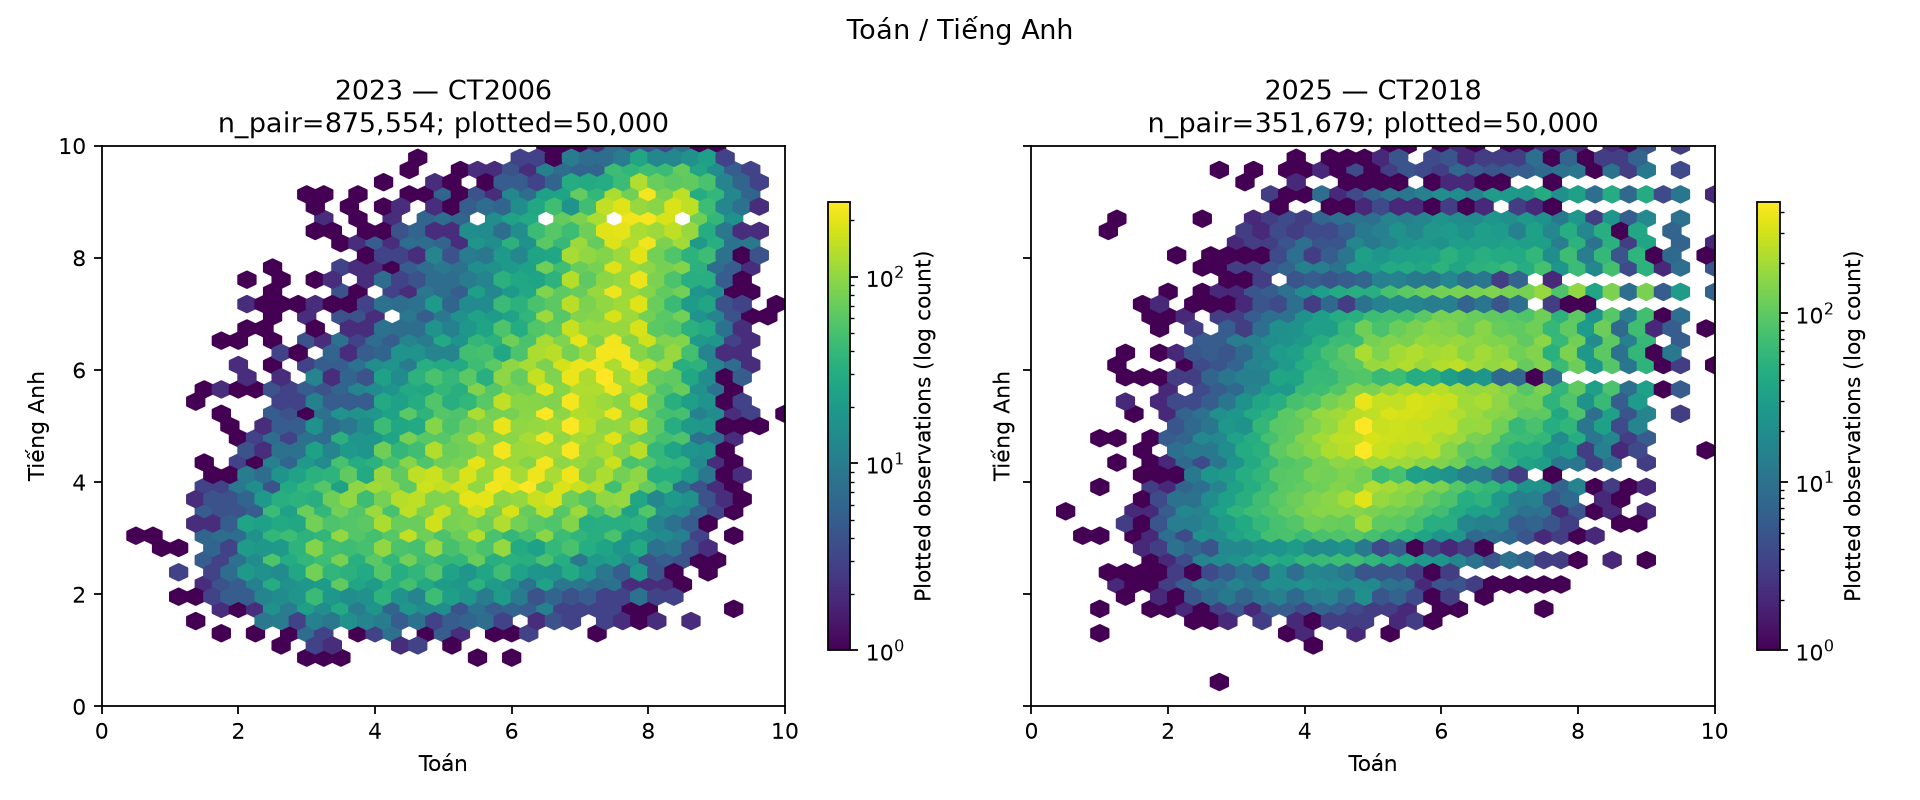

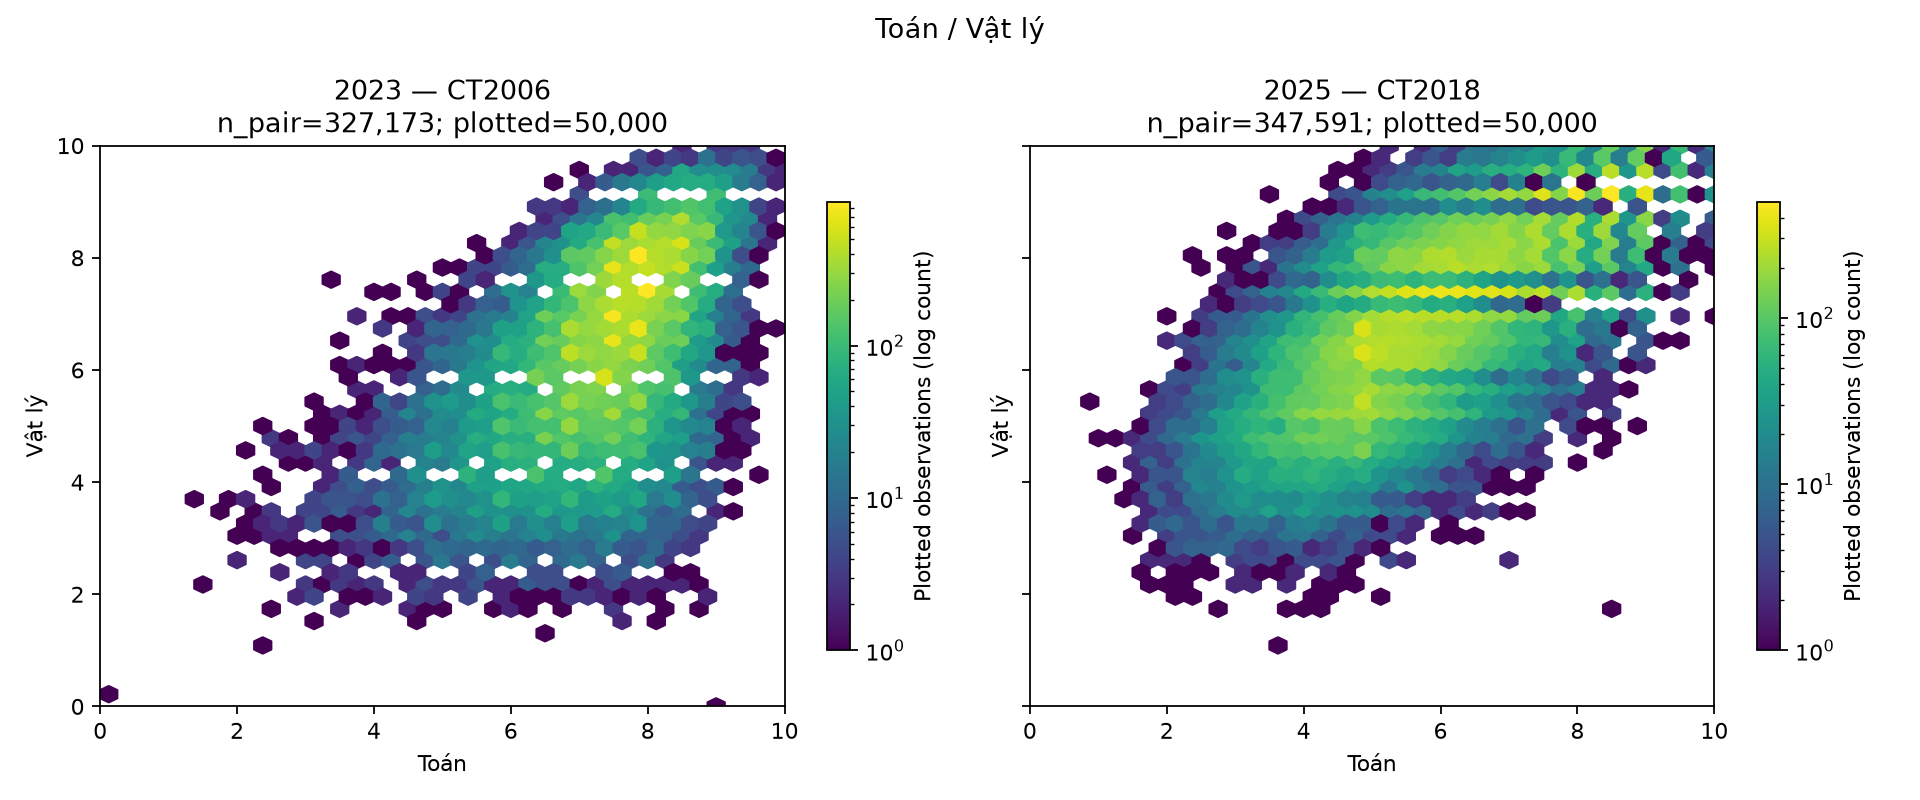

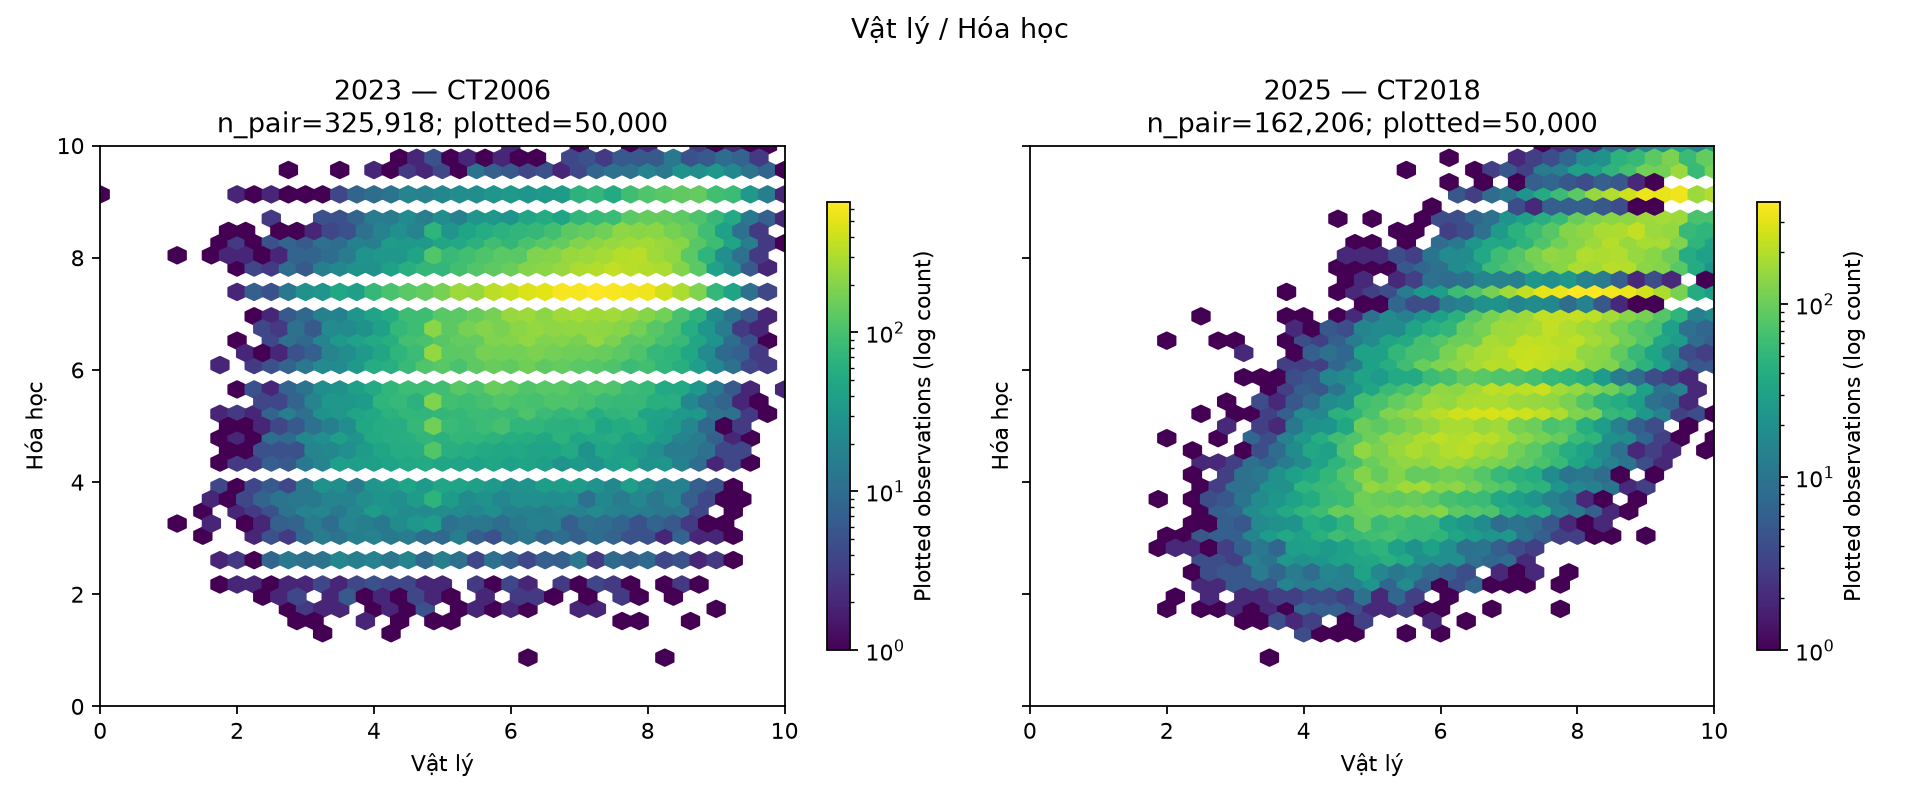

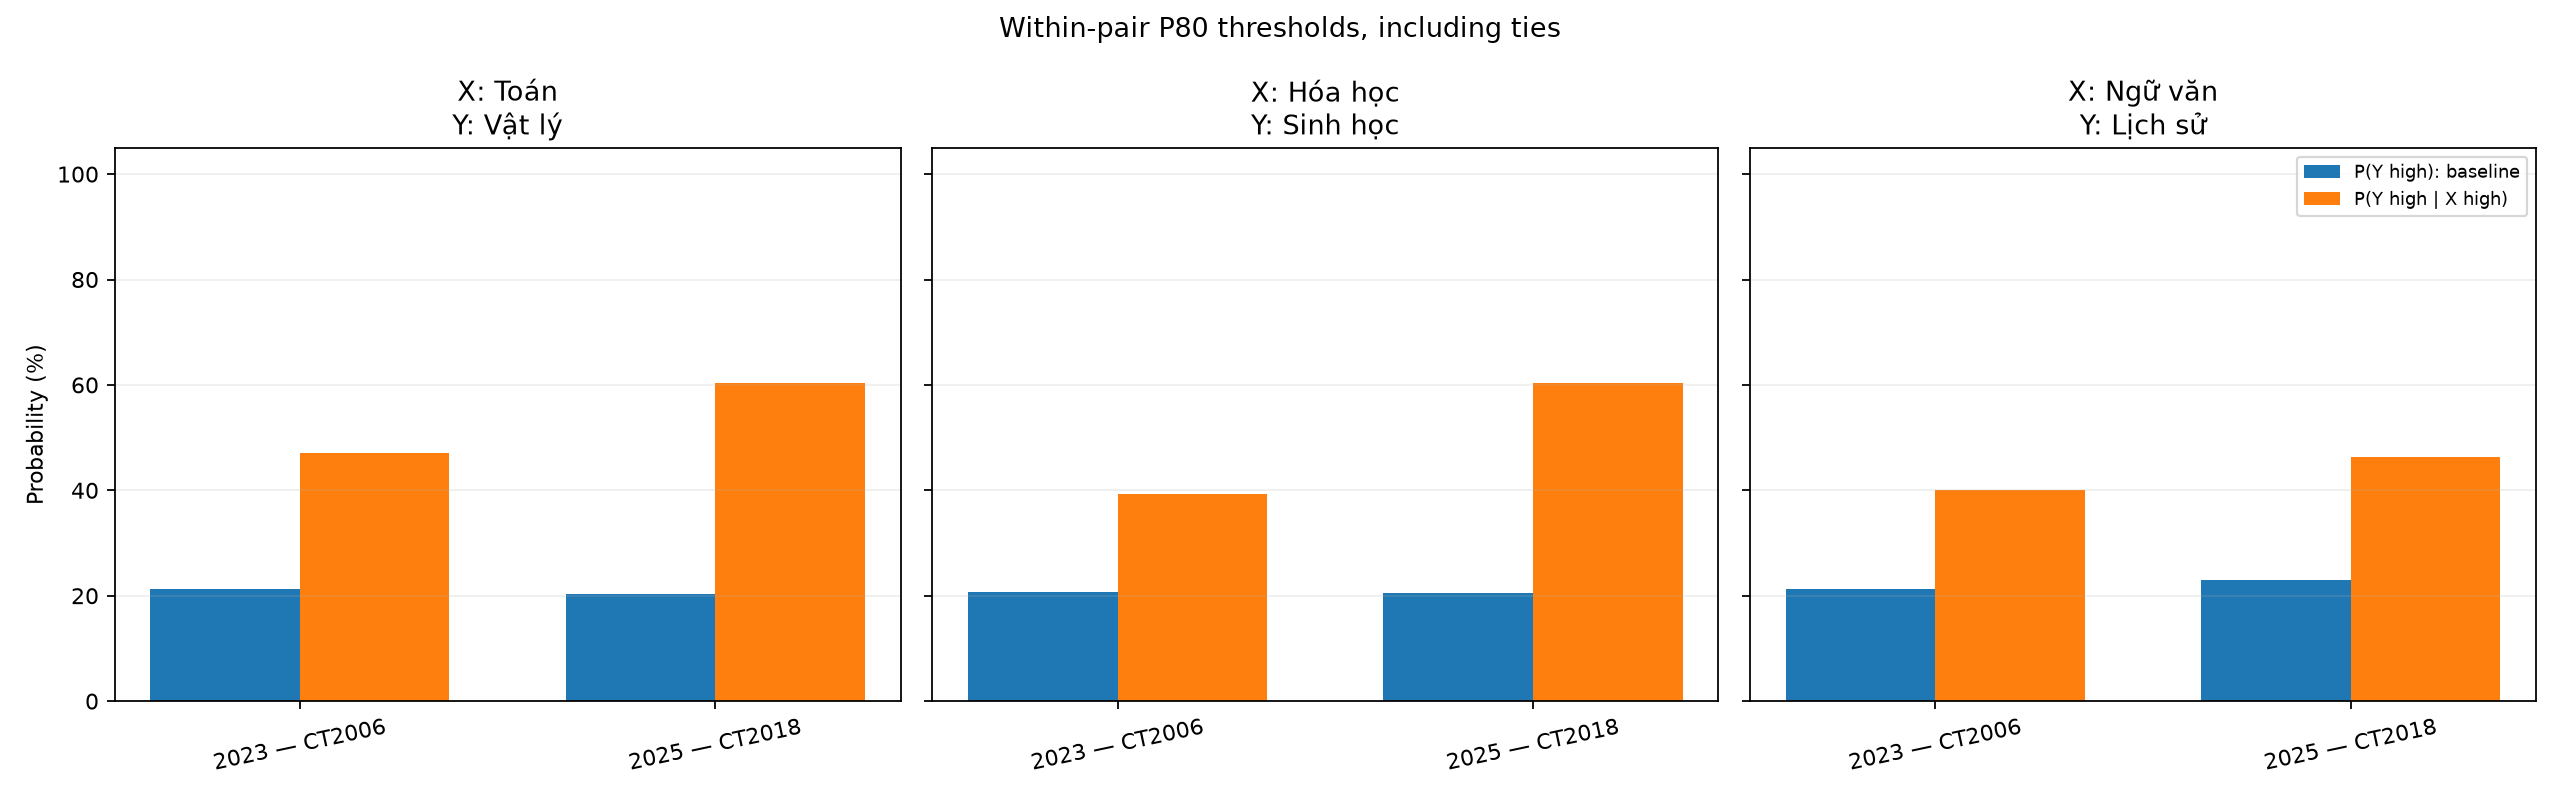

# Báo cáo phân tích điểm thi THPT — Phần 3 và 5

**2023 — CT2006** so với **2025 — CT2018**. Phạm vi: đủ 24 tổ hợp, cơ cấu môn có điểm, ngưỡng top 10%/20% và tương quan giữa các môn.

## Kết quả chính — đọc phần này trước

Báo cáo trả lời đủ ba yêu cầu: **xu hướng môn thi**, **điểm tổ hợp và ngưỡng top 10%/20%**, **tương quan giữa các môn**. Các bảng chi tiết và hình ở phía sau đều có diễn giải ngay bên dưới. Dùng 2023 so với 2025 xuyên suốt; không thay năm gốc bằng 2024.

### 3.1. Xu hướng môn thi: môn nào có tỷ lệ tăng hoặc giảm?

Trong dữ liệu điểm, chỉ quan sát được người có bài thi/điểm. Vì vậy, “xu hướng chọn môn” dưới đây là **xu hướng tỷ lệ có điểm**, chưa phải tỷ lệ đăng ký ban đầu. Mẫu số: 1,017,584 người năm 2023 và 1,130,984 người năm 2025 có ít nhất một điểm thi.

| Môn | Có điểm 2023 | Có điểm 2025 | Biến động số người | So với số người 2023 (%) | Tỷ lệ 2023 (%) | Tỷ lệ 2025 (%) | Biến động tỷ lệ (điểm phần trăm) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Toán | 1.003.373 | 1.126.172 | Tăng 122.799 | Tăng 12,24 | 98,60 | 99,57 | Tăng 0,97 |
| Ngữ văn | 1.008.239 | 1.126.726 | Tăng 118.487 | Tăng 11,75 | 99,08 | 99,62 | Tăng 0,54 |
| Tiếng Anh | 876.102 | 351.848 | Giảm 524.254 | Giảm 59,84 | 86,10 | 31,11 | Giảm 54,99 |
| Vật lý | 327.189 | 347.599 | Tăng 20.410 | Tăng 6,24 | 32,15 | 30,73 | Giảm 1,42 |
| Hóa học | 328.118 | 240.135 | Giảm 87.983 | Giảm 26,81 | 32,24 | 21,23 | Giảm 11,01 |
| Sinh học | 324.625 | 69.895 | Giảm 254.730 | Giảm 78,47 | 31,90 | 6,18 | Giảm 25,72 |
| Lịch sử | 683.447 | 481.293 | Giảm 202.154 | Giảm 29,58 | 67,16 | 42,56 | Giảm 24,61 |
| Địa lý | 682.134 | 476.472 | Giảm 205.662 | Giảm 30,15 | 67,03 | 42,13 | Giảm 24,91 |
| Ngoại ngữ (mọi mã) | 880.997 | 357.723 | Giảm 523.274 | Giảm 59,40 | 86,58 | 31,63 | Giảm 54,95 |

**Diễn giải bảng:** Toán tăng 122.799 người (+12,24%), tỷ lệ tăng 0,97 điểm phần trăm; Văn tăng 118.487 người (+11,75%), tỷ lệ tăng 0,54 điểm phần trăm. Anh giảm từ 86,10% xuống 31,11% (−54,99 điểm phần trăm); Sinh giảm 31,90% → 6,18% (−25,72); Địa giảm 67,03% → 42,13% (−24,91); Sử giảm 67,16% → 42,56% (−24,61); Hóa giảm 32,24% → 21,23% (−11,01). **Lý tăng 20.410 bài nhưng tỷ lệ vẫn giảm 32,15% → 30,73%** vì tổng số người có điểm tăng. Anh là tập con của Ngoại ngữ; hai hàng này không cộng với nhau. Đây là thay đổi cơ cấu tập dự thi, chưa đủ để kết luận học sinh giảm hứng thú với môn học.

**Cách tính và đọc tăng/giảm:** n là số thí sinh có điểm hợp lệ 0–10 ở riêng cột môn đó (giữ điểm 0, không điền điểm thiếu). Tỷ lệ có điểm = 100 × n / số người có ít nhất một điểm cùng năm. Biến động số người = n2025 − n2023; % tăng/giảm số người = 100 × (n2025 / n2023 − 1). Biến động tỷ lệ = tỷ lệ 2025 − tỷ lệ 2023, đơn vị **điểm phần trăm**. Phép trừ cho biết hướng thay đổi: dương là tăng, âm là giảm. Ví dụ Lý tăng 6,24% số người, nhưng tỷ lệ giảm 1,42 điểm phần trăm vì tổng người có điểm tăng 11,14%.

**Đếm từng môn độc lập cho cả hai năm:** 2023 Lý 327.189, Hóa 328.118, Sinh 324.625; Sử 683.447, Địa 682.134. Không dùng chung 327.189 cho cả ba môn tự nhiên và không dùng một số chung cho các môn xã hội. Một người có điểm ở nhiều môn được tính một lần trong từng môn. Ba số đếm 2023 (Toán, Lý, Hóa) cao hơn công bố mỗi môn 1 người; giữ số đếm từ file và nêu sai lệch tại mục đối chiếu nguồn, chưa tự loại người khi chưa xác định nguyên nhân.

**Tỷ lệ đăng ký cần dữ liệu khác:** số đăng ký môn / tổng người đăng ký trong cùng phạm vi. Tỷ lệ có điểm trong người đăng ký môn = số có điểm / số đăng ký môn, cần ghép đúng năm, chương trình và phạm vi thí sinh. Hai file điểm chưa cung cấp số đăng ký và tình trạng miễn/vắng thi, nên hai tỷ lệ này chưa tính được. Không gọi tỷ lệ có điểm trên bảng là tỷ lệ đăng ký.

**Vì sao cơ chế thi quan trọng?** Năm 2023, học sinh THPT xét tốt nghiệp thường thi Toán, Văn, Ngoại ngữ và một bài KHTN (Lý/Hóa/Sinh) hoặc KHXH (Sử/Địa/GDCD). Năm 2025 CT2018, Toán/Văn bắt buộc, chỉ chọn hai môn còn lại đã học ở lớp 12 (Ngoại ngữ có ngoại lệ về ngôn ngữ). Vì vậy, không thể diễn giải giảm số bài Sinh như một thay đổi độc lập về sở thích: trước đây thi KHTN thường có cả ba điểm, nay Hóa và Sinh cạnh tranh với các môn tự chọn khác. [Quy chế 2023](https://vqa.moet.gov.vn/vi/laws/detail/Van-ban-hop-nhat-Thong-tu-ban-hanh-Quy-che-thi-tot-nghiep-trung-hoc-pho-thong-31/?download=1&id=0), [Điều 20 quy chế 2025](https://vqa.moet.gov.vn/uploads/news/2024_12/final-quy-che-thi-tot-nghiep-thpt.pdf).

| Môn riêng theo chương trình | Năm | Có điểm | Tỷ lệ có điểm (%) |
| --- | --- | --- | --- |
| GDCD | 2023 | 565452 | 55.57 |
| GDKT&PL | 2025 | 246401 | 21.79 |
| Tin học | 2025 | 7602 | 0.67 |
| Công nghệ | 2025 | 24338 | 2.15 |

**Diễn giải bảng:** GDKT&PL, Tin học và Công nghệ có số liệu 2025, nhưng không gán tỷ lệ 2023 bằng 0 để tính “tăng trưởng”. Tin/Công nghệ chưa có bài thi tương ứng năm 2023; GDCD và GDKT&PL khác nội dung. GDCD 2023 vẫn được đếm riêng và hiển thị đầy đủ, không ghép thành một môn bất biến với GDKT&PL. Công nghệ trong CSV gộp hai định hướng Công nghiệp và Nông nghiệp nên chỉ phân tích tổng gộp.

### 3.2. Điểm các tổ hợp thay đổi thế nào?

| Tổ hợp | Đủ điểm 2023 | Đủ điểm 2025 | TB 2023 | TB 2025 | Thay đổi TB |
| --- | --- | --- | --- | --- | --- |
| A00 | 325902 | 162200 | 20.77 | 19.37 | -1.41 |
| A01 | 314412 | 146960 | 20.27 | 18.87 | -1.41 |
| A02 | 322538 | 4795 | 20.43 | 15.32 | -5.11 |
| A08 | 564507 | 68313 | 20.29 | 17.29 | -3.00 |
| A09 | 564517 | 109404 | 20.38 | 17.39 | -2.99 |
| B00 | 324554 | 44964 | 20.60 | 18.29 | -2.32 |
| B08 | 313063 | 4227 | 20.07 | 15.66 | -4.41 |
| C00 | 681723 | 297377 | 18.97 | 19.72 | 0.75 |
| C01 | 320523 | 345014 | 21.01 | 20.09 | -0.92 |
| C02 | 320465 | 237064 | 21.17 | 19.11 | -2.06 |
| C03 | 669692 | 476660 | 18.48 | 17.28 | -1.20 |
| C04 | 668369 | 472025 | 18.61 | 17.29 | -1.32 |
| C14 | 564516 | 246298 | 21.17 | 18.46 | -2.71 |
| C19 | 565211 | 68351 | 21.44 | 20.25 | -1.19 |
| C20 | 565249 | 109423 | 21.53 | 20.31 | -1.22 |
| D01 | 873126 | 350654 | 18.89 | 18.58 | -0.31 |
| D07 | 313538 | 24478 | 20.42 | 17.51 | -2.91 |
| D08 | 313063 | 4227 | 20.07 | 15.66 | -4.41 |
| D09 | 557198 | 69904 | 17.00 | 17.86 | 0.86 |
| D10 | 557086 | 53567 | 17.09 | 18.19 | 1.10 |
| D14 | 557405 | 69989 | 18.15 | 20.45 | 2.29 |
| D15 | 557312 | 53592 | 18.25 | 20.63 | 2.38 |
| D66 | 556185 | 47905 | 20.31 | 21.11 | 0.80 |
| D84 | 556034 | 47902 | 19.15 | 18.56 | -0.60 |

**Diễn giải bảng:** A00 giảm trung bình 1,41 điểm, B00 giảm 2,32; C00 tăng 0,75; D01 giảm 0,31. Mỗi hàng chỉ xét người đủ ba môn của hàng đó. **B00 giảm 324.554 → 44.964 người (−86,15%)**: đây là quy mô nhóm đủ Toán/Hóa/Sinh. Năm 2025 có 69.895 người có điểm Sinh, nhưng chỉ 44.964 người đồng thời có Hóa và Toán; không được lấy toàn bộ người có Sinh làm B00. Một người vẫn có thể xuất hiện ở nhiều hàng (ví dụ đủ Toán/Văn/Lý/Hóa thuộc A00, C01, C02). Bảy mã có GDCD/GDKT&PL chỉ so sánh mô tả theo mã, không xem nội dung môn bất biến.

### 3.3. “Điểm chuẩn ảo”: bao nhiêu điểm để vào top 20% hoặc top 10%?

**Thang tổng 30 điểm, không ưu tiên hay nhân hệ số.** Top 20% dùng P80; top 10% dùng P90 trên tập người đủ điểm của từng tổ hợp/năm. Đây là ngưỡng phân phối, không phải điểm trúng tuyển. Dấu “thay đổi” luôn là 2025 trừ 2023.

| Tổ hợp | Top 20% 2023 | Top 20% 2025 | Top 10% 2023 | Top 10% 2025 | Thay đổi top 10% |
| --- | --- | --- | --- | --- | --- |
| A00 | 23.40 | 23.50 | 24.45 | 25.25 | 0.80 |
| A01 | 23.25 | 22.10 | 24.55 | 23.75 | -0.80 |
| A02 | 22.75 | 17.75 | 23.70 | 19.35 | -4.35 |
| A08 | 23.35 | 20.00 | 24.50 | 21.20 | -3.30 |
| A09 | 23.05 | 20.10 | 24.10 | 21.25 | -2.85 |
| B00 | 22.90 | 22.60 | 23.95 | 24.75 | 0.80 |
| B08 | 22.75 | 18.50 | 23.90 | 20.25 | -3.65 |
| C00 | 22.00 | 23.75 | 23.25 | 25.25 | 2.00 |
| C01 | 23.25 | 23.00 | 24.15 | 24.25 | 0.10 |
| C02 | 23.35 | 22.25 | 24.15 | 24.00 | -0.15 |
| C03 | 21.80 | 20.50 | 23.20 | 21.75 | -1.45 |
| C04 | 21.60 | 20.50 | 22.80 | 22.00 | -0.80 |
| C14 | 24.05 | 21.00 | 25.10 | 22.10 | -3.00 |
| C19 | 24.25 | 23.00 | 25.50 | 24.25 | -1.25 |
| C20 | 24.00 | 23.10 | 25.00 | 24.25 | -0.75 |
| D01 | 22.40 | 21.00 | 23.85 | 22.50 | -1.35 |
| D07 | 23.05 | 20.75 | 24.20 | 22.50 | -1.70 |
| D08 | 22.75 | 18.50 | 23.90 | 20.25 | -3.65 |
| D09 | 20.55 | 20.50 | 22.35 | 21.75 | -0.60 |
| D10 | 20.35 | 20.75 | 22.05 | 22.25 | 0.20 |
| D14 | 21.50 | 23.00 | 23.25 | 24.00 | 0.75 |
| D15 | 21.25 | 23.00 | 22.90 | 24.00 | 1.10 |
| D66 | 23.40 | 23.25 | 25.00 | 24.25 | -0.75 |
| D84 | 22.50 | 20.75 | 24.20 | 22.25 | -1.95 |

**Diễn giải bảng:** Với A00, ngưỡng top 10% tăng **24,45 → 25,25**, dù trung bình giảm. B00 cũng tăng **23,95 → 24,75**; C00 tăng **23,25 → 25,25**; D01 giảm **23,85 → 22,50**. Ví dụ, người đạt 25,25 A00 năm 2025 chạm ngưỡng P90 của nhóm đủ điểm A00 trong dữ liệu. Đồng hạng ở ngưỡng khiến nhóm “đạt từ ngưỡng trở lên” có thể lớn hơn đúng 10%; bảng chi tiết phía sau ghi riêng tỷ lệ lớn hơn và lớn hơn hoặc bằng ngưỡng.

**Kết luận từ hai bảng tổ hợp:** điểm trung bình giảm không kéo theo mọi ngưỡng top đều giảm. Ở A00/B00, phần giữa và đuôi cao dịch chuyển khác hướng. Thay đổi lựa chọn môn làm tập người được so sánh khác nhau, nên không đồng nhất kết quả này với mức thay đổi năng lực của cùng một nhóm học sinh.

### 5. Tương quan: môn nào thường đạt cao cùng nhau?

| Cặp môn | r 2023 | r 2025 | Thay đổi r | Số cặp 2023 | Số cặp 2025 |
| --- | --- | --- | --- | --- | --- |
| Toán – Ngữ văn | 0.46 | 0.38 | -0.08 | 994167 | 1121925 |
| Toán – Tiếng Anh | 0.59 | 0.50 | -0.10 | 875554 | 351679 |
| Toán – Vật lý | 0.57 | 0.71 | 0.14 | 327173 | 347591 |
| Vật lý – Hóa học | 0.38 | 0.75 | 0.37 | 325918 | 162206 |
| Hóa học – Sinh học | 0.41 | 0.74 | 0.34 | 324571 | 44964 |
| Lịch sử – Địa lý | 0.61 | 0.76 | 0.15 | 681846 | 297403 |

**Diễn giải bảng:** r nằm trong [−1;1]. r dương lớn nghĩa là điểm hai môn có xu hướng tăng cùng nhau; gần 0 nghĩa là liên hệ tuyến tính yếu trong đúng nhóm có đủ hai điểm. Sử–Địa tăng khoảng **0,608 → 0,759**, còn Toán–Anh giảm **0,592 → 0,497**. Đây là hệ số của các nhóm người có điểm khác nhau giữa hai năm; không kết luận việc học một môn làm tăng điểm môn kia. Pearson, Spearman, cỡ mẫu và hình mật độ được trình bày chi tiết phía sau.

**Giới hạn của mục tiêu nghiên cứu:** dữ liệu cho thấy thay đổi điểm trong bối cảnh đổi chương trình và cách thi. Hai năm quan sát không tách được phần tác động riêng của chương trình 2018, dạng đề, cách chấm, lựa chọn môn và thành phần thí sinh. Không dùng tương quan để khẳng định độ phân biệt câu hỏi.

## Bằng chứng từ phổ điểm: tăng/giảm ở phần nào?

Đây là phần bổ trợ để giải thích cơ cấu môn thi và điểm tổ hợp. **Mẫu số tại đây là người có điểm của riêng môn đó trong từng năm**, khác với tỷ lệ có điểm trên toàn bộ thí sinh ở mục 3.1. Chuẩn hóa về % giúp so hình dạng phổ khi số người thi khác nhau. Các thống kê dùng điểm gốc; chỉ hình vẽ gộp khoảng 0,5 điểm.

| Môn | TB 2023 → 2025 | Trung vị | Dưới 5 (%) | Từ 8 (%) | Từ 9 (%) |
| --- | --- | --- | --- | --- | --- |
| Toán | 6,25 → 4,78 | 6,60 → 4,60 | 21,64 → 56,39 | 15,16 → 5,45 | 1,00 → 1,43 |
| Ngữ văn | 6,86 → 7,00 | 7,00 → 7,25 | 7,31 → 6,24 | 24,42 → 26,69 | 4,30 → 3,91 |
| Vật lý | 6,57 → 6,99 | 6,75 → 7,00 | 14,79 → 9,79 | 21,32 → 30,79 | 2,97 → 11,53 |
| Hóa học | 6,74 → 6,06 | 7,00 → 6,00 | 11,70 → 29,53 | 22,67 → 19,29 | 3,42 → 7,43 |
| Sinh học | 6,39 → 5,78 | 6,50 → 5,75 | 10,40 → 32,44 | 10,57 → 10,83 | 1,68 → 2,54 |
| Lịch sử | 6,03 → 6,52 | 6,00 → 6,60 | 24,91 → 18,63 | 13,07 → 23,03 | 3,06 → 6,88 |
| Địa lý | 6,15 → 6,63 | 6,25 → 6,75 | 13,35 → 18,69 | 6,64 → 26,68 | 0,87 → 11,26 |
| Tiếng Anh | 5,45 → 5,38 | 5,20 → 5,25 | 44,83 → 38,22 | 15,04 → 5,39 | 5,29 → 1,35 |
| Ngoại ngữ (mọi mã) | 5,46 → 5,41 | 5,20 → 5,25 | 44,69 → 37,86 | 15,18 → 6,05 | 5,38 → 1,80 |

**Diễn giải bảng:** Mọi mũi tên đi từ 2023 sang 2025. Trung vị mô tả phần giữa; dưới 5, từ 8 và từ 9 mô tả các vùng điểm. Nhóm từ 9 nằm trong nhóm từ 8 nên không cộng hai tỷ lệ này. Trung bình có thể giảm dù tỷ lệ dưới 5 giảm, nếu phần điểm cao cũng thu hẹp (như Tiếng Anh). Trung bình tăng cũng không có nghĩa mọi phần của phổ tăng (như Địa lý).

![Phổ điểm chuẩn hóa của chín mục môn/ngoại ngữ](../outputs/audits/subject_distributions.png)

**Diễn giải hình:** Đường xanh là 2023, cam là 2025; chiều cao mỗi khoảng là % người trong đúng môn/năm đó. Các ô dùng cùng thang trục; mỗi đường cộng đủ 100%. So phần bên trái mốc 5 và bên phải mốc 8 để kiểm tra các kết luận bên dưới. Điểm thi rời rạc và bước điểm khác nhau có thể tạo răng cưa; không suy ra nguyên nhân chỉ từ một đỉnh. Ngoại ngữ gồm Tiếng Anh và các ngôn ngữ khác, không phải một nhóm độc lập với Anh.

**Toán:** TB 6,25 → 4,78; trung vị 6,60 → 4,60; dưới 5: 21,64 → 56,39% người; từ 8: 15,16 → 5,45%; từ 9: 1,00 → 1,43%. Phần giữa thấp hơn rõ và nhóm dưới 5 lớn hơn, phù hợp trung bình giảm. Tuy nhiên tỷ lệ từ 9 tăng: không thể nói mọi nhóm điểm đều giảm.

**Ngữ văn:** TB 6,86 → 7,00; trung vị 7,00 → 7,25; dưới 5: 7,31 → 6,24% người; từ 8: 24,42 → 26,69%; từ 9: 4,30 → 3,91%. Phần giữa cao hơn, dưới 5 giảm và từ 8 tăng, phù hợp trung bình tăng; tỷ lệ từ 9 lại giảm nên đuôi cao nhất không cùng chiều với trung bình.

**Vật lý:** TB 6,57 → 6,99; trung vị 6,75 → 7,00; dưới 5: 14,79 → 9,79% người; từ 8: 21,32 → 30,79%; từ 9: 2,97 → 11,53%. Dưới 5 thu hẹp, trung vị tăng và nhóm từ 8, từ 9 mở rộng: nhiều vùng của phổ cùng phù hợp với trung bình tăng.

**Hóa học:** TB 6,74 → 6,06; trung vị 7,00 → 6,00; dưới 5: 11,70 → 29,53% người; từ 8: 22,67 → 19,29%; từ 9: 3,42 → 7,43%. Dưới 5 mở rộng mạnh, trung vị giảm và từ 8 thu hẹp, phù hợp trung bình giảm. Từ 9 vẫn tăng nên nhóm rất cao biến động khác phần giữa.

**Sinh học:** TB 6,39 → 5,78; trung vị 6,50 → 5,75; dưới 5: 10,40 → 32,44% người; từ 8: 10,57 → 10,83%; từ 9: 1,68 → 2,54%. Dưới 5 tăng mạnh và trung vị giảm, phù hợp trung bình giảm; từ 8 gần như giữ mức cũ và từ 9 tăng. Không thể quy toàn bộ nhóm thi thành yếu hơn.

**Lịch sử:** TB 6,03 → 6,52; trung vị 6,00 → 6,60; dưới 5: 24,91 → 18,63% người; từ 8: 13,07 → 23,03%; từ 9: 3,06 → 6,88%. Dưới 5 giảm, trung vị tăng và các nhóm từ 8, từ 9 tăng: phổ có nhiều bằng chứng phù hợp với trung bình cao hơn.

**Địa lý:** TB 6,15 → 6,63; trung vị 6,25 → 6,75; dưới 5: 13,35 → 18,69% người; từ 8: 6,64 → 26,68%; từ 9: 0,87 → 11,26%. Dưới 5 và các nhóm từ 8, từ 9 đều tăng; trung vị và trung bình vẫn tăng. Hai vùng thấp/cao đều mở rộng, không phải toàn bộ phổ dịch đều sang phải.

**Tiếng Anh:** TB 5,45 → 5,38; trung vị 5,20 → 5,25; dưới 5: 44,83 → 38,22% người; từ 8: 15,04 → 5,39%; từ 9: 5,29 → 1,35%. Dưới 5 giảm và trung vị nhích lên, nhưng từ 8 và từ 9 thu hẹp rất mạnh. Trung bình giảm nhẹ phản ánh thay đổi cả hình dạng, không thể tóm thành cả phổ giảm hoặc đề khó hơn cho mọi người.

**Ngoại ngữ (mọi mã):** TB 5,46 → 5,41; trung vị 5,20 → 5,25; dưới 5: 44,69 → 37,86% người; từ 8: 15,18 → 6,05%; từ 9: 5,38 → 1,80%. Mẫu gộp cho xu hướng gần Tiếng Anh vì Anh chiếm đa số. Cơ cấu ngôn ngữ cũng thay đổi nên đánh giá môn Anh phải dùng riêng N1, không dùng trung bình gộp.

**Bằng chứng về cơ chế và giới hạn kết luận:** Quy chế chuyển từ bài tổ hợp sang hai môn tự chọn làm thay đổi cách hình thành nhóm dự thi. Định dạng đề 2025 cũng thay đổi, trong đó nhiều môn có thêm dạng đúng/sai hoặc trả lời ngắn; Ngoại ngữ vẫn dùng dạng nhiều lựa chọn. [Cấu trúc do Bộ GDĐT công bố](https://vqa.moet.gov.vn/vi/news/thong-bao/cau-truc-dinh-dang-de-thi-tot-nghiep-thpt-tu-nam-2025-74.html). Đây là bằng chứng các điều kiện đánh giá thay đổi, chưa chứng minh mỗi điều kiện gây ra bao nhiêu điểm. Phổ điểm cho biết kết quả tăng/giảm ở đâu; không đo trực tiếp sở thích, năng lực trước kỳ thi hay độ khó câu hỏi trên cùng một nhóm thí sinh.

**Giả thuyết có thể thảo luận:** Với Lý và Sử, tăng nhóm điểm cao phù hợp với khả năng nhóm tự chọn có sở trường hoặc định hướng xét tuyển rõ hơn. Địa có biến động hai vùng nên cần diễn giải thận trọng hơn. Hóa/Sinh có trung bình giảm dù được tự chọn, và Toán bắt buộc cũng giảm trung bình; các kết quả này bác bỏ cách giải thích đơn giản “được tự chọn thì điểm chắc chắn tăng”. Đề thi, cách chấm, quá trình học và thành phần thí sinh là các yếu tố cần nghiên cứu thêm. Chưa ước lượng được tác động riêng của chương trình 2018 từ hai kỳ thi.

[Bảng số liệu tái lập](../outputs/audits/subject_distribution_evidence.csv) · [Tần suất các khoảng điểm](../outputs/audits/subject_distribution_bins.csv).

## Ý tưởng nghiên cứu: nhóm nào đóng góp biến động điểm cao?

**Trạng thái:** Các bảng điểm cao và phân rã theo vùng điểm dưới đây đã được tính từ dữ liệu. Các giải thích về giảng dạy, định dạng đề và tự lựa chọn là giả thuyết nghiên cứu; chưa được kiểm định nhân quả. Phân nhóm theo địa phương, trường hoặc năng lực đầu vào là hướng tiếp theo, chưa có kết quả trong báo cáo này.

### Điểm từ 9 và điểm 10: tăng số lượng hay chỉ tăng tỷ lệ?

| Môn | Số người ≥9 (2023 → 2025) | Tỷ lệ ≥9 (%) | Số điểm 10 | Tỷ lệ điểm 10 (%) |
| --- | --- | --- | --- | --- |
| Toán | 10.040 → 16.156 | 1,00 → 1,43 | 12 → 513 | 0,0012 → 0,0456 |
| Ngữ văn | 43.384 → 44.000 | 4,30 → 3,91 | 1 → 0 | 0,0001 → 0,0000 |
| Vật lý | 9.704 → 40.089 | 2,97 → 11,53 | 70 → 3.929 | 0,0214 → 1,1303 |
| Hóa học | 11.238 → 17.839 | 3,42 → 7,43 | 137 → 625 | 0,0418 → 0,2603 |
| Sinh học | 5.451 → 1.775 | 1,68 → 2,54 | 135 → 82 | 0,0416 → 0,1173 |
| Lịch sử | 20.936 → 33.112 | 3,06 → 6,88 | 789 → 1.518 | 0,1154 → 0,3154 |
| Địa lý | 5.933 → 53.670 | 0,87 → 11,26 | 35 → 6.907 | 0,0051 → 1,4496 |
| Tiếng Anh | 46.306 → 4.755 | 5,29 → 1,35 | 494 → 141 | 0,0564 → 0,0401 |
| Ngoại ngữ (mọi mã) | 47.372 → 6.453 | 5,38 → 1,80 | 555 → 417 | 0,0630 → 0,1166 |
| GDCD | 200.469 → — | 35,45 → — | 14.693 → — | 2,5985 → — |
| GDKT&PL | — → 35.243 | — → 14,30 | — → 1.451 | — → 0,5889 |
| Tin học | — → 644 | — → 8,47 | — → 60 | — → 0,7893 |
| Công nghệ | — → 3.540 | — → 14,55 | — → 105 | — → 0,4314 |

**Diễn giải bảng:** Mẫu số là người có điểm của riêng môn/năm. Số người từ 9 và số điểm 10 trả lời về quy mô; tỷ lệ trả lời về cơ cấu. Sinh từ 9 giảm 5.451 → 1.775 người dù tỷ lệ tăng 1,68% → 2,54%; số điểm 10 cũng giảm 135 → 82. Ngược lại, Lý và Hóa tăng cả số người từ 9 lẫn tỷ lệ. Vì vậy không gộp mọi môn vào nhận xét “điểm 9/10 đều tăng”. Văn từ 9 tăng nhẹ số người nhưng giảm tỷ lệ. Tỷ lệ điểm 10 hiển thị bốn chữ số thập phân để tránh làm tròn tỷ lệ rất nhỏ thành 0. Điểm 10 thuộc nhóm từ 9, Anh thuộc Ngoại ngữ nên không cộng trùng. Dấu — là không có mốc tương ứng; GDCD và GDKT&PL vẫn để riêng.

### Phân rã mô tả: vùng điểm nào đóng góp vào chênh lệch trung bình?

Chia mỗi môn thành bốn vùng không chồng lấn: 0–<5, 5–<8, 8–<9 và 9–10. Đóng góp của một vùng = tổng điểm của người trong vùng / tổng số người có điểm môn đó. Tổng bốn đóng góp bằng trung bình môn. Lấy đóng góp 2025 trừ 2023 để xác định phần thay đổi gắn với từng vùng; đơn vị là điểm trên thang 10.

| Môn | 0–<5 | 5–<8 | 8–<9 | 9–10 | Tổng thay đổi TB |
| --- | --- | --- | --- | --- | --- |
| Toán | 1.21 | -1.88 | -0.84 | 0.04 | -1.47 |
| Ngữ văn | -0.05 | 0.01 | 0.22 | -0.04 | 0.14 |
| Vật lý | -0.18 | -0.30 | 0.08 | 0.81 | 0.41 |
| Hóa học | 0.70 | -1.15 | -0.60 | 0.38 | -0.68 |
| Sinh học | 0.87 | -1.52 | -0.05 | 0.08 | -0.62 |
| Lịch sử | -0.25 | -0.13 | 0.52 | 0.36 | 0.49 |
| Địa lý | 0.20 | -1.51 | 0.81 | 0.98 | 0.48 |
| Tiếng Anh | -0.14 | 0.91 | -0.48 | -0.36 | -0.08 |
| Ngoại ngữ (mọi mã) | -0.15 | 0.89 | -0.47 | -0.33 | -0.06 |

**Diễn giải bảng:** Bốn cột vùng cộng lại thành cột cuối; số làm tròn có thể lệch 0,01. Ví dụ một cột 9–10 dương cho biết phần điểm do vùng này đóng góp vào trung bình lớn hơn, trong khi tổng trung bình vẫn có thể giảm nếu các cột khác giảm nhiều hơn. **Cột 0–<5 dương không có nghĩa kết quả tốt hơn**: có thể vì tỷ trọng vùng thấp lớn hơn. Đây là phép phân rã phân phối, không theo dõi cùng người qua hai năm và không xác định nguyên nhân. “Nhóm 9–10” là nhóm theo kết quả, chưa cho biết họ học trường nào hay có năng lực ban đầu ra sao.

**Đọc trường hợp Hóa/Sinh:** Ở Hóa, vùng 9–10 đóng góp thêm khoảng 0,38 điểm vào trung bình, nhưng vùng 5–<8 giảm đóng góp khoảng 1,15 và vùng 8–<9 giảm khoảng 0,60; tổng thay đổi vẫn âm sau cộng đủ bốn vùng. Ở Sinh, vùng 9–10 tăng đóng góp khoảng 0,08, trong khi vùng 5–<8 giảm khoảng 1,52. Hai ví dụ cho thấy tỷ lệ điểm rất cao tăng có thể cùng tồn tại với trung bình giảm, không tạo mâu thuẫn thống kê.

[Dữ liệu vùng điểm và đóng góp trung bình](../outputs/audits/subject_score_band_contributions.csv).

### Làm thế nào xác định nhóm thí sinh đứng sau biến động?

Câu hỏi đề xuất: “Trong từng môn, thay đổi tỷ lệ từ 9/điểm 10 tập trung ở nhóm nào, và đi kèm thay đổi quy mô nhóm hay thay đổi tỷ lệ điểm cao ngay trong nhóm?” Có thể chia theo hội đồng thi/tỉnh nếu xác minh đúng bảng mã SBD từng năm; theo trường, hệ THPT/GDTX hoặc thí sinh tự do nếu bổ sung được biến tương ứng. Không suy trường, phòng thi hoặc chỗ ngồi chỉ từ các SBD gần nhau.

Với điểm hiện có, có thể nghiên cứu hồ sơ điểm các môn khác: người đạt ≥9 Hóa có điểm Toán/Văn thế nào, có đồng thời đạt cao ở môn tự chọn còn lại không? Điểm thiếu do không thi không phải 0. So thứ hạng Toán/Văn trong từng năm chỉ mô tả vị trí tương đối, không tạo ra thước đo năng lực tuyệt đối tương đương giữa hai năm. Phần phân tích tiếp theo đã chia nhóm theo thứ hạng Toán/Văn; chưa có thước đo năng lực đầu vào độc lập hoặc dữ liệu trường/địa phương đã xác minh để phân nhóm.

Nếu các nhóm g không chồng lấn và bao phủ toàn bộ người có điểm môn đó, tỷ lệ điểm cao toàn môn = Σ(tỷ trọng nhóm g × tỷ lệ điểm cao trong nhóm g). So hai năm để tách biến động cơ cấu nhóm khỏi biến động trong nhóm. Cần thống nhất định nghĩa nhóm và nêu nhóm thiếu thông tin. 24 tổ hợp chồng lấn theo lựa chọn đa nhãn nên không cộng trực tiếp chúng để phân rã tổng thí sinh.

### Các giả thuyết giải thích cần giữ riêng

| Giả thuyết | Cơ chế dự kiến | Bằng chứng cần thêm |
| --- | --- | --- |
| Kết quả học tập thay đổi | Chương trình, dạy học, ôn tập và mức thích nghi ảnh hưởng kết quả | Năng lực đầu vào/đánh giá độc lập tương đương và thông tin quá trình học |
| Định dạng và quy tắc chấm thay đổi | Điểm từng phần thay đổi khác nhau theo mức nắm chắc kiến thức | Đáp án từng câu, điểm từng phần; thiết kế đối sánh phù hợp |
| Thành phần tự chọn môn thay đổi | Sở trường, ngành muốn học và lựa chọn xét tuyển làm nhóm dự thi khác trước | Đăng ký môn, định hướng xét tuyển và năng lực trước thi |
| Nội dung/độ khó đề hoặc tiêu chí chấm khác | Các vùng điểm chịu ảnh hưởng khác nhau | Đối sánh đề/câu hỏi hoặc bài viết và dữ liệu chấm; tổng điểm chưa đủ |

**Diễn giải bảng:** Đây là những cơ chế có thể đồng thời tồn tại. Chưa có dữ liệu để xếp “đề thuận lợi hơn” cao hay thấp hơn “giảng dạy tốt hơn”. Cùng mục đích thi không bảo đảm đề tương đương độ khó; thiếu bằng chứng về một cơ chế không xác nhận cơ chế khác. Chỉ đối sánh điểm khi các điều kiện về nội dung và năng lực đo lường phù hợp. [Tài liệu ETS về đối sánh điểm](https://www.ets.org/Media/Research/pdf/LIVINGSTON2ed.pdf).

**Lý, Sử và Địa:** Lý và Sử có dưới 5 giảm, từ 8 tăng; có thể đặt giả thuyết kết quả học tập tốt hơn, nhóm tự chọn có thế mạnh hơn hoặc cách đánh giá khác. Địa có cả dưới 5 và từ 8 tăng nên cần xét các vùng riêng. Quy mô Sử/Địa đều giảm trong dataset; chưa có căn cứ nói số đăng ký hai môn tăng hoặc lựa chọn 2023 là ngẫu nhiên. Lý tăng số người có điểm nhưng giảm nhẹ tỷ trọng, gợi ý duy trì quy mô dự thi sau tự chọn; chưa đo trực tiếp mức yêu thích.

**Hóa và Sinh:** Giả thuyết yêu cầu đánh giá mới ảnh hưởng nhóm giữa nhiều hơn nhóm rất cao; hoặc mức chuẩn bị/thích nghi không đồng đều; hoặc nhóm chọn môn theo ngành học dù môn đó chưa phải sở trường. Các mẫu dưới 5 tăng và tỷ lệ từ 9 tăng phù hợp để nghiên cứu các giả thuyết này, chưa xác nhận giả thuyết nào. Số người thi ít đi tự nó không làm trung bình giảm.

**Tiếng Anh:** Nhóm dưới 5 và từ 8 đều thu hẹp trong khi trung vị nhích lên. Có thể giả thuyết mức cơ bản tiếp cận được hơn nhưng điểm cao khó đạt; hoặc thành phần nhóm tự chọn thay đổi, gồm khả năng một phần người rất mạnh và rất yếu đều chọn hướng khác. Ngoại ngữ chỉ dùng câu nhiều lựa chọn; không lấy đúng/sai hay trả lời ngắn giải thích trực tiếp biến động Anh. Giả thuyết về lựa chọn khác cần dữ liệu đăng ký để kiểm tra.

### Giả thuyết cụ thể về đúng/sai và trả lời ngắn

Theo quy tắc công bố, câu đúng/sai bốn ý cho 0,10/0,25/0,50/1,00 điểm khi đúng 1/2/3/4 ý. Đúng ý cuối làm điểm câu tăng 0,50, nên cách chấm có thể tạo khác biệt giữa người nắm một phần và người nắm chắc. Trả lời ngắn không có phương án đáp án để chọn. Có thể giả thuyết các dạng này thay đổi kết quả từng vùng điểm, nhưng không mặc định làm trung bình giảm hoặc tăng. Phân phối rộng hơn chưa đủ chứng minh khả năng phân biệt năng lực tốt hơn; cần dữ liệu từng câu và bằng chứng đo lường. [Cách chấm công bố](https://xaydungchinhsach.chinhphu.vn/cau-truc-de-thi-tot-nghiep-thpt-tu-nam-2025-119240308200554932.htm), [phạm vi áp dụng các dạng câu hỏi](https://vqa.moet.gov.vn/vi/news/thong-bao/cau-truc-dinh-dang-de-thi-tot-nghiep-thpt-tu-nam-2025-74.html).

### Ngữ văn: giả thuyết riêng cho bài tự luận

Văn vẫn thi tự luận; trọng số Đọc hiểu/Làm văn chuyển từ 3/7 năm 2023 sang Đọc hiểu/Viết 4/6 năm 2025. [Cấu trúc 2023](https://xaydungchinhsach.chinhphu.vn/tot-nghiep-thpt-2023-bi-quyet-dat-diem-cao-mon-ngu-van-khong-nen-bo-lo-119230614084944406.htm), [cấu trúc 2025](https://xaydungchinhsach.chinhphu.vn/cau-truc-de-thi-tot-nghiep-thpt-tu-nam-2025-119240308200554932.htm). TB tăng 6,86 → 7,00, trung vị 7,00 → 7,25; từ 8 tăng 24,42% → 26,69% nhưng từ 9 giảm 4,30% → 3,91%. Giả thuyết gồm kỹ năng đọc/viết thay đổi, cấu trúc và nội dung thuận lợi cho vùng điểm khá, hoặc tiêu chí chấm làm kết quả tập trung hơn ở vùng giữa. Thay đổi trọng số có thể tăng hoặc giảm điểm tùy mức đạt ở từng phần; chưa biết chiều tác động nếu thiếu điểm thành phần. Không suy ra “chấm rộng tay” hoặc chương trình tốt hơn chỉ từ phổ tổng điểm.

### Có thể suy ra gian lận từ điểm cao tăng không?

**Chưa thể.** Điểm 9/10 tăng, một địa phương tăng mạnh hay một hồ sơ điểm lệch giữa các môn đều chưa đủ kết luận gian lận. Cần xét quy mô mẫu, cơ cấu tự chọn, thay đổi đề/cách chấm, chất lượng và nguồn dữ liệu. So nhiều nhóm dễ xuất hiện cực trị ngẫu nhiên; nếu kiểm định hàng loạt phải xử lý việc so sánh nhiều lần và nêu độ bất định. Phát hiện thống kê chỉ xác định đối tượng cần kiểm tra dữ liệu thêm; báo cáo này chưa triển khai phát hiện bất thường và không gắn nhãn cá nhân hay địa phương.

Để đánh giá nghi vấn cần bằng chứng độc lập như đáp án từng câu có mức trùng sai bất thường sau khi xét mã đề/năng lực, dữ liệu phòng thi hoặc biên bản xác minh. Ngay cả dấu hiệu từ đáp án cũng cần được thẩm tra. ETS kết hợp phân tích thống kê với các bước xem xét khác khi đánh giá tính hợp lệ của điểm. [Nghiên cứu về trùng đáp án bất thường](https://www.ets.org/research/policy_research_reports/publications/report/2017/jxrq.html), [quy trình xem xét điểm](https://www.ets.org/pdfs/about/why-how-questions.pdf).

**Kết luận nghiên cứu phù hợp:** “Xác định các nhóm và vùng điểm đóng góp vào biến động điểm cao; thảo luận các cơ chế có thể giải thích và những dữ liệu cần bổ sung.” Không chuyển câu hỏi thành kết luận ai gây biến động hoặc ai gian lận khi chưa có bằng chứng.

## Phân tích tiếp: hồ sơ điểm của nhóm đóng góp biến động

**Đã tính:** Chia người có điểm của từng môn thành bốn nhóm theo thứ hạng điểm Toán trong toàn bộ người có Toán của cùng năm; thiếu Toán thành nhóm riêng. Riêng khi phân tích môn Toán dùng thứ hạng Văn, tránh dùng chính điểm cần giải thích để tạo nhóm. Đồng điểm nhận thứ hạng trung bình nên mỗi nhóm không nhất thiết đúng 25% số người. Nhóm không chồng lấn và bao phủ mọi người có điểm môn mục tiêu. Không gán thiếu điểm bằng 0.

**Phạm vi suy luận:** Đây là hồ sơ điểm tương đối trong từng năm, chưa phải nhóm năng lực đầu vào hoặc thước đo tương đương giữa hai đề. Chênh lệch còn chịu ảnh hưởng của thay đổi môn tham chiếu, cơ cấu tự chọn và kỳ thi. Không xem điều chỉnh theo nhóm này là kiểm soát đầy đủ yếu tố nhiễu hoặc ước lượng tác động riêng của chương trình.

### Số người điểm cao trong từng nhóm hồ sơ

| Môn | Nhóm theo môn tham chiếu | Số có điểm môn | Số đạt ≥9 | Tỷ lệ ≥9 trong nhóm (%) | Số điểm 10 | Góp thay đổi ≥9 (điểm %) |
| --- | --- | --- | --- | --- | --- | --- |
| Toán | Hạng ≤25% / Ngữ văn | 270.579 → 304.736 | 1.163 → 2.053 | 0,43 → 0,67 | 1 → 66 | 0.07 |
| Toán | Hạng >25–50% / Ngữ văn | 198.407 → 243.606 | 1.631 → 3.044 | 0,82 → 1,25 | 1 → 110 | 0.11 |
| Toán | Hạng >50–75% / Ngữ văn | 280.822 → 274.211 | 3.319 → 4.727 | 1,18 → 1,72 | 4 → 156 | 0.09 |
| Toán | Hạng >75% / Ngữ văn | 244.359 → 299.372 | 3.661 → 6.218 | 1,50 → 2,08 | 6 → 177 | 0.19 |
| Toán | Thiếu điểm tham chiếu / Ngữ văn | 9.206 → 4.247 | 266 → 114 | 2,89 → 2,68 | 0 → 4 | -0.02 |
| Ngữ văn | Hạng ≤25% / Toán | 243.030 → 282.552 | 1.661 → 2.545 | 0,68 → 0,90 | 0 → 0 | 0.06 |
| Ngữ văn | Hạng >25–50% / Toán | 243.168 → 286.096 | 5.761 → 7.188 | 2,37 → 2,51 | 0 → 0 | 0.07 |
| Ngữ văn | Hạng >50–75% / Toán | 250.879 → 272.275 | 13.465 → 13.086 | 5,37 → 4,81 | 0 → 0 | -0.17 |
| Ngữ văn | Hạng >75% / Toán | 257.090 → 281.002 | 22.174 → 20.960 | 8,62 → 7,46 | 1 → 0 | -0.34 |
| Ngữ văn | Thiếu điểm tham chiếu / Toán | 14.072 → 4.801 | 323 → 221 | 2,30 → 4,60 | 0 → 0 | -0.01 |
| Tiếng Anh | Hạng ≤25% / Toán | 173.830 → 21.654 | 286 → 46 | 0,16 → 0,21 | 2 → 2 | -0.02 |
| Tiếng Anh | Hạng >25–50% / Toán | 213.255 → 64.546 | 1.677 → 206 | 0,79 → 0,32 | 11 → 6 | -0.13 |
| Tiếng Anh | Hạng >50–75% / Toán | 237.564 → 115.205 | 9.148 → 638 | 3,85 → 0,55 | 63 → 20 | -0.86 |
| Tiếng Anh | Hạng >75% / Toán | 250.905 → 150.274 | 35.146 → 3.862 | 14,01 → 2,57 | 418 → 113 | -2.91 |
| Tiếng Anh | Thiếu điểm tham chiếu / Toán | 548 → 169 | 49 → 3 | 8,94 → 1,78 | 0 → 0 | -0.00 |
| Vật lý | Hạng ≤25% / Toán | 7.531 → 18.076 | 2 → 3 | 0,03 → 0,02 | 0 → 0 | 0.00 |
| Vật lý | Hạng >25–50% / Toán | 37.582 → 53.130 | 8 → 91 | 0,02 → 0,17 | 0 → 1 | 0.02 |
| Vật lý | Hạng >50–75% / Toán | 103.195 → 99.033 | 276 → 1.528 | 0,27 → 1,54 | 0 → 26 | 0.36 |
| Vật lý | Hạng >75% / Toán | 178.865 → 177.352 | 9.418 → 38.467 | 5,27 → 21,69 | 70 → 3.902 | 8.19 |
| Vật lý | Thiếu điểm tham chiếu / Toán | 16 → 8 | 0 → 0 | 0,00 → 0,00 | 0 → 0 | 0.00 |
| Hóa học | Hạng ≤25% / Toán | 7.553 → 12.370 | 0 → 2 | 0,00 → 0,02 | 0 → 0 | 0.00 |
| Hóa học | Hạng >25–50% / Toán | 37.663 → 37.350 | 15 → 19 | 0,04 → 0,05 | 0 → 0 | 0.00 |
| Hóa học | Hạng >50–75% / Toán | 103.425 → 69.691 | 543 → 273 | 0,53 → 0,39 | 0 → 1 | -0.05 |
| Hóa học | Hạng >75% / Toán | 179.456 → 120.718 | 10.680 → 17.542 | 5,95 → 14,53 | 137 → 622 | 4.05 |
| Hóa học | Thiếu điểm tham chiếu / Toán | 21 → 6 | 0 → 3 | 0,00 → 50,00 | 0 → 2 | 0.00 |
| Sinh học | Hạng ≤25% / Toán | 7.258 → 11.900 | 1 → 0 | 0,01 → 0,00 | 0 → 0 | -0.00 |
| Sinh học | Hạng >25–50% / Toán | 37.244 → 16.530 | 16 → 6 | 0,04 → 0,04 | 0 → 0 | 0.00 |
| Sinh học | Hạng >50–75% / Toán | 102.369 → 18.685 | 399 → 52 | 0,39 → 0,28 | 1 → 3 | -0.05 |
| Sinh học | Hạng >75% / Toán | 177.725 → 22.779 | 5.035 → 1.717 | 2,83 → 7,54 | 134 → 79 | 0.91 |
| Sinh học | Thiếu điểm tham chiếu / Toán | 29 → 1 | 0 → 0 | 0,00 → 0,00 | 0 → 0 | 0.00 |
| Lịch sử | Hạng ≤25% / Toán | 235.539 → 191.672 | 1.716 → 3.376 | 0,73 → 1,76 | 71 → 111 | 0.45 |
| Lịch sử | Hạng >25–50% / Toán | 205.582 → 154.172 | 4.586 → 9.103 | 2,23 → 5,90 | 167 → 367 | 1.22 |
| Lịch sử | Hạng >50–75% / Toán | 148.206 → 94.752 | 6.472 → 11.527 | 4,37 → 12,17 | 204 → 511 | 1.45 |
| Lịch sử | Hạng >75% / Toán | 80.506 → 36.197 | 5.996 → 7.893 | 7,45 → 21,81 | 201 → 425 | 0.76 |
| Lịch sử | Thiếu điểm tham chiếu / Toán | 13.614 → 4.500 | 2.166 → 1.213 | 15,91 → 26,96 | 146 → 104 | -0.06 |
| Địa lý | Hạng ≤25% / Toán | 235.069 → 196.498 | 351 → 5.331 | 0,15 → 2,71 | 1 → 520 | 1.07 |
| Địa lý | Hạng >25–50% / Toán | 205.273 → 153.315 | 1.129 → 15.767 | 0,55 → 10,28 | 3 → 1.716 | 3.14 |
| Địa lý | Hạng >50–75% / Toán | 147.901 → 90.244 | 1.792 → 19.118 | 1,21 → 21,18 | 11 → 2.455 | 3.75 |
| Địa lý | Hạng >75% / Toán | 80.249 → 32.003 | 2.000 → 11.928 | 2,49 → 37,27 | 14 → 1.903 | 2.21 |
| Địa lý | Thiếu điểm tham chiếu / Toán | 13.642 → 4.412 | 661 → 1.526 | 4,85 → 34,59 | 6 → 313 | 0.22 |
| Ngoại ngữ (mọi mã) | Hạng ≤25% / Toán | 174.469 → 22.097 | 299 → 87 | 0,17 → 0,39 | 2 → 5 | -0.01 |
| Ngoại ngữ (mọi mã) | Hạng >25–50% / Toán | 214.208 → 65.833 | 1.754 → 388 | 0,82 → 0,59 | 12 → 31 | -0.09 |
| Ngoại ngữ (mọi mã) | Hạng >50–75% / Toán | 239.129 → 117.275 | 9.477 → 1.171 | 3,96 → 1,00 | 84 → 90 | -0.75 |
| Ngoại ngữ (mọi mã) | Hạng >75% / Toán | 252.633 → 152.347 | 35.790 → 4.804 | 14,17 → 3,15 | 457 → 291 | -2.72 |
| Ngoại ngữ (mọi mã) | Thiếu điểm tham chiếu / Toán | 558 → 171 | 52 → 3 | 9,32 → 1,75 | 0 → 0 | -0.01 |

**Diễn giải bảng:** Mũi tên là 2023 → 2025. “Số có điểm môn” là mẫu số cho tỷ lệ đạt ≥9 ngay trong nhóm. “Góp thay đổi ≥9” lấy phần người điểm cao của nhóm trên tổng người có điểm toàn môn năm 2025 trừ năm 2023; cộng năm nhóm bằng thay đổi tỷ lệ ≥9 toàn môn. Đây không phải biến động của cùng các cá nhân. Nhóm thiếu điểm thường ít người, có nhóm dưới 100; đọc số đếm và tránh suy rộng từ tỷ lệ nhóm nhỏ. Ngoại ngữ gồm Tiếng Anh, không cộng hai mục này thành tổng độc lập.

### Tách thay đổi cơ cấu nhóm và thay đổi trong nhóm

| Môn | Tổng thay đổi ≥9 (điểm %) | Phần cơ cấu nhóm | Phần thay đổi trong nhóm | Thay đổi tỷ lệ điểm 10 (điểm %) |
| --- | --- | --- | --- | --- |
| Toán | 0.43 | -0.01 | 0.44 | 0.04 |
| Ngữ văn | -0.40 | -0.08 | -0.32 | -0.00 |
| Tiếng Anh | -3.93 | 1.23 | -5.16 | -0.02 |
| Vật lý | 8.57 | -0.51 | 9.08 | 1.11 |
| Hóa học | 4.00 | -0.46 | 4.47 | 0.22 |
| Sinh học | 0.86 | -1.16 | 2.02 | 0.08 |
| Lịch sử | 3.82 | -0.87 | 4.68 | 0.20 |
| Địa lý | 10.39 | -1.31 | 11.71 | 1.44 |
| Ngoại ngữ (mọi mã) | -3.57 | 1.26 | -4.84 | 0.05 |

**Diễn giải bảng:** Hai phần cộng thành tổng thay đổi tỷ lệ ≥9. Phần cơ cấu phản ánh nhóm hồ sơ chiếm tỷ trọng khác trong người thi môn đó; phần trong nhóm phản ánh tỷ lệ ≥9 của các nhóm cùng tên thay đổi. Dùng phép phân rã đối xứng với trọng số trung bình hai năm, không chọn một năm làm chuẩn tùy ý. Đây là đẳng thức mô tả; “trong nhóm” vẫn chứa thay đổi đề, lựa chọn thí sinh, năng lực và các yếu tố khác, không phải tác động thuần của chương trình. Mỗi môn có thể dùng nhóm tham chiếu khác, như Toán dùng Văn.

| Môn | Tổng thay đổi TB | Phần cơ cấu nhóm | Phần thay đổi trong nhóm |
| --- | --- | --- | --- |
| Toán | -1.47 | -0.00 | -1.46 |
| Ngữ văn | 0.14 | -0.01 | 0.15 |
| Tiếng Anh | -0.08 | 0.39 | -0.47 |
| Vật lý | 0.41 | -0.13 | 0.54 |
| Hóa học | -0.68 | -0.14 | -0.54 |
| Sinh học | -0.62 | -0.47 | -0.15 |
| Lịch sử | 0.49 | -0.12 | 0.61 |
| Địa lý | 0.48 | -0.14 | 0.62 |
| Ngoại ngữ (mọi mã) | -0.06 | 0.39 | -0.45 |

**Diễn giải bảng:** Đơn vị ở đây là điểm trên thang 10, khác điểm phần trăm ở bảng trên. Hai phần cộng thành chênh lệch trung bình. Nếu phần cơ cấu dương nhưng tổng âm, thay đổi trung bình trong các nhóm đã kéo kết quả theo hướng ngược lại mạnh hơn. Các nhóm chỉ giữ vị trí tương đối; không khẳng định cùng chất lượng học sinh giữa hai năm.

![Đóng góp của các nhóm hồ sơ vào biến động tỷ lệ từ 9](../outputs/audits/subject_group_contributions.png)

**Diễn giải hình:** Mỗi ô là đóng góp ròng của một nhóm vào chênh lệch tỷ lệ ≥9 toàn môn, đơn vị điểm phần trăm; mỗi hàng cộng thành thay đổi toàn môn. Màu đỏ là đóng góp tăng, xanh là giảm. Màu thể hiện kết quả theo nhóm, không phải chỉ số bất thường hay nghi vấn gian lận. Nhóm của Toán được xác định bằng Văn; các hàng khác dùng Toán.

**Vật lý — nhóm hạng Toán >75%:** chiếm 54,67 → 51,02% người có điểm môn này; tỷ lệ đạt ≥9 ngay trong nhóm 5,27 → 21,69%; số người đạt ≥9 9.418 → 38.467. Các tỷ lệ này dùng mẫu số khác nhau: tỷ trọng nhóm trên toàn môn và tỷ lệ điểm cao trong nhóm.

**Hóa học — nhóm hạng Toán >75%:** chiếm 54,69 → 50,27% người có điểm môn này; tỷ lệ đạt ≥9 ngay trong nhóm 5,95 → 14,53%; số người đạt ≥9 10.680 → 17.542. Các tỷ lệ này dùng mẫu số khác nhau: tỷ trọng nhóm trên toàn môn và tỷ lệ điểm cao trong nhóm.

**Sinh học — nhóm hạng Toán >75%:** chiếm 54,75 → 32,59% người có điểm môn này; tỷ lệ đạt ≥9 ngay trong nhóm 2,83 → 7,54%; số người đạt ≥9 5.035 → 1.717. Các tỷ lệ này dùng mẫu số khác nhau: tỷ trọng nhóm trên toàn môn và tỷ lệ điểm cao trong nhóm.

**Tiếng Anh — nhóm hạng Toán >75%:** chiếm 28,64 → 42,71% người có điểm môn này; tỷ lệ đạt ≥9 ngay trong nhóm 14,01 → 2,57%; số người đạt ≥9 35.146 → 3.862. Các tỷ lệ này dùng mẫu số khác nhau: tỷ trọng nhóm trên toàn môn và tỷ lệ điểm cao trong nhóm.

**Lịch sử — nhóm hạng Toán >75%:** chiếm 11,78 → 7,52% người có điểm môn này; tỷ lệ đạt ≥9 ngay trong nhóm 7,45 → 21,81%; số người đạt ≥9 5.996 → 7.893. Các tỷ lệ này dùng mẫu số khác nhau: tỷ trọng nhóm trên toàn môn và tỷ lệ điểm cao trong nhóm.

**Địa lý — nhóm hạng Toán >75%:** chiếm 11,76 → 6,72% người có điểm môn này; tỷ lệ đạt ≥9 ngay trong nhóm 2,49 → 37,27%; số người đạt ≥9 2.000 → 11.928. Các tỷ lệ này dùng mẫu số khác nhau: tỷ trọng nhóm trên toàn môn và tỷ lệ điểm cao trong nhóm.

**Phát hiện cần thảo luận:** Với Anh, tỷ trọng nhóm có thứ hạng Toán cao tăng nhưng tỷ lệ Anh ≥9 trong nhóm này giảm; chỉ nói “ít người thi nên điểm giảm” không mô tả đủ kết quả. Với Hóa và Sinh, nhóm hạng Toán >75% chiếm tỷ trọng thấp hơn nhưng tỷ lệ đạt ≥9 trong nhóm cao hơn. Đây là bằng chứng bổ sung về hồ sơ điểm, chưa phân biệt được thay đổi năng lực, đề/cách chấm hay cơ chế tự lựa chọn. Phân nhóm theo trường/địa phương và kiểm tra bất thường vẫn chưa được thực hiện.

[Bảng nhóm và số đếm](../outputs/audits/subject_group_profiles.csv) · [Phân rã từng nhóm](../outputs/audits/subject_group_decomposition.csv) · [Tổng hợp thay đổi](../outputs/audits/subject_group_changes.csv).

## Đối chiếu internet: điểm, phổ điểm và điều kiện thi

Đối chiếu ngày **17/10/2026** với báo cáo thống kê Bộ GDĐT ngày 15/7/2025 trên Cổng Chính phủ và bảng phổ điểm 2023 do cơ quan nhà nước đăng lại. Đếm số bài và tần số phải khớp chính xác; điểm trung bình/độ lệch chuẩn được so trong sai số làm tròn công bố 0,005. [PDF gốc 2025](https://bcp.cdnchinhphu.vn/334894974524682240/2025/7/15/bao-cao-15-7-2025-version3-1-1752569726486925110557.pdf), [bảng 9 môn 2023](https://dbndnghean.vn/cong-bo-diem-thi-tot-nghiep-trung-hoc-pho-thong-nam-2023-9656.htm), [đối chứng Toán/Lý/Hóa 2023 trên Cổng Chính phủ](https://xaydungchinhsach.chinhphu.vn/pho-diem-cac-mon-toan-vat-ly-hoa-hoc-thi-tot-nghiep-thpt-2023-119230718104051335.htm).

| Năm | Môn | Số bài trên máy | Số bài công bố | Lệch số bài | Cột phổ điểm khớp |
| --- | --- | --- | --- | --- | --- |
| 2023 | Toán | 1003373 | 1003372 | 1 | 50/51 |
| 2023 | Ngữ văn | 1008239 | 1008239 | 0 | 41/41 |
| 2023 | Vật lý | 327189 | 327188 | 1 | 40/41 |
| 2023 | Hóa học | 328118 | 328117 | 1 | 40/41 |
| 2023 | Sinh học | 324625 | 324625 | 0 | 41/41 |
| 2023 | Lịch sử | 683447 | 683447 | 0 | 41/41 |
| 2023 | Địa lý | 682134 | 682134 | 0 | 41/41 |
| 2023 | GDCD | 565452 | 565452 | 0 | 41/41 |
| 2023 | Tiếng Anh | 876102 | 876102 | 0 | 51/51 |
| 2025 | Toán | 1126172 | 1126172 | 0 | 20/20 |
| 2025 | Ngữ văn | 1126726 | 1126726 | 0 | 40/40 |
| 2025 | Vật lý | 347599 | 347599 | 0 | 40/40 |
| 2025 | Hóa học | 240135 | 240135 | 0 | 40/40 |
| 2025 | Sinh học | 69895 | 69895 | 0 | 40/40 |
| 2025 | Tin học | 7602 | 7602 | 0 | 40/40 |
| 2025 | Lịch sử | 481293 | 481293 | 0 | 40/40 |
| 2025 | Địa lý | 476472 | 476472 | 0 | 40/40 |
| 2025 | GDKT&PL | 246401 | 246401 | 0 | 40/40 |
| 2025 | Tiếng Anh | 351848 | 351848 | 0 | 40/40 |
| 2025 | Công nghệ | 24338 | 24338 | 0 | 40/40 |

**Diễn giải bảng:** Năm 2025, cả **11 nhóm môn trong CSV khớp số bài và toàn bộ 420 cột phổ điểm** (Toán chia khoảng 0,5; các môn còn lại 0,25, khoảng đóng bên phải; điểm 0 ở khoảng đầu). **106/106 chỉ số tổng hợp được đối chiếu đều khớp**, gồm số bài, trung bình, trung vị, độ lệch chuẩn, mốt, số điểm 0/10, số ≤1, số <5 và số ≥7 khi tài liệu có chỉ tiêu tương ứng. Công nghệ trên máy chỉ đối chiếu tổng Công nghiệp + Nông nghiệp, không xác minh riêng từng định hướng.

**Sai lệch 2023 còn phải công bố:** Toán có thêm một bài ở mức 4,4; Lý thêm một bài ở mức 2,0; Hóa thêm một bài ở mức 4,0 so với bảng ban đầu. Vì đều dưới 5, số bài dưới 5 cũng hơn một mỗi môn. Chưa có bằng chứng xác định nguyên nhân (thời điểm thu thập, cập nhật hay sai nguồn); không tự xóa một thí sinh để ép khớp. Các ngưỡng và hệ số báo cáo vẫn tính từ file nguồn hiện có.

**Văn 2023 cần phân biệt điểm gốc và cách hiển thị phổ:** có **3.962 điểm không nằm đúng lưới 0,25**. Điểm gốc cho 73.656 bài <5, còn công bố ghi 73.622. Khi chỉ để đối chiếu, đưa điểm gốc về mốc 0,25 gần nhất thì **41/41 tần số công bố khớp và số <5 bằng 73.622**. Sự khớp này là bằng chứng về cách biểu diễn/gom điểm, chưa phải xác nhận trực tiếp quy trình làm tròn của Bộ. Không làm tròn điểm gốc khi tính tổ hợp hoặc tương quan.

**Điều kiện thi 2025 được kiểm tra trong dữ liệu:** không có người nào có quá hai điểm tự chọn (không đếm Anh lần nữa cạnh Ngoại ngữ). Có 1.120.879 người đủ hai điểm tự chọn, 9.700 người chỉ có một, 557 người không có điểm tự chọn; trong nhóm cuối có thể thiếu/vắng/bảo lưu hoặc thuộc diện khác, không tự kết luận sai quy chế từ ô trống. Điều 20 cho phép thí sinh đã tốt nghiệp đăng ký các môn theo nguyện vọng, tối đa hai môn tự chọn. Năm 2025 có cả đề CT2006 và CT2018; cohort trong báo cáo là file CT2018 người dùng xác nhận, không gán mọi dữ liệu mang năm 2025 thành CT2018. [Thông tư 24/2024, Điều 2 và Điều 20](https://vqa.moet.gov.vn/uploads/news/2024_12/final-quy-che-thi-tot-nghiep-thpt.pdf).

**Dạng đề/cách chấm đã đổi:** một số môn 2025 thêm câu đúng–sai và trả lời ngắn. Trong một câu đúng–sai bốn ý, đúng 1/2/3/4 ý lần lượt được 0,10/0,25/0,50/1,00 điểm. Không áp dụng mô tả “ba dạng câu” cho mọi môn: Ngoại ngữ dùng nhiều lựa chọn; cấu trúc cụ thể tùy môn. Vì vậy, cùng thang 10 không bảo đảm cùng phép đo hay cùng độ khó. [Cục Quản lý chất lượng: định dạng đề](https://vqa.moet.gov.vn/vi/news/thong-bao/cau-truc-dinh-dang-de-thi-tot-nghiep-thpt-tu-nam-2025-74.html), [thang điểm từng dạng trên Cổng Chính phủ](https://xaydungchinhsach.chinhphu.vn/cau-truc-de-thi-tot-nghiep-thpt-tu-nam-2025-119240308200554932.htm).

**Danh mục tổ hợp nguồn có lỗi mô tả:** không dùng nguyên xi `danh_muc_to_hop.csv` làm quy tắc tính. Ví dụ Toán/Văn/Hóa là C02, không phải D04; D04 là Toán/Văn/Tiếng Trung; D09 dùng Toán/Sử/Anh, D10 dùng Toán/Địa/Anh. Bảng mapping 24 mã trong báo cáo đã dùng ba môn tường minh và đối chiếu lại các tổng `diem_*`. Không coi A01 đồng nghĩa D90 hoặc B08 đồng nghĩa D99 như ghi chú nguồn. [ĐHQGHN, bảng môn theo mã năm 2025](https://sis.vnu.edu.vn/Images/images/2025/CHUY%E1%BB%82N%20B%C3%80I%20WEB/250725_-Thong-bao-ve-bang-quy-doi-tuong-duong-va-chenh-cac-to-hop_-Ban-dang-web-2.pdf), [ĐH KHTN: tổ hợp 2025](https://hus.vnu.edu.vn/thong-bao/dao-tao-tuyen-sinh/thong-bao-diem-nguong-dam-bao-chat-luong-nam-2025-142145).

**Phương pháp thống kê:** ngưỡng P80/P90 theo inverse empirical CDF là một lựa chọn hợp lệ, cần nêu rõ vì khác cách nội suy mặc định. Pearson đo liên hệ tuyến tính, Spearman đo liên hệ thứ hạng/đơn điệu; n≥100 là ngưỡng chất lượng do dự án chọn, không phải định luật thống kê. [NumPy quantile](https://numpy.org/doc/stable/reference/generated/numpy.quantile.html), [SciPy Pearson](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html), [SciPy Spearman](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html).

**Mức xác nhận đạt được:** năm 2025 khớp rất tốt ở mức tổng hợp/phổ môn; năm 2023 có các khác biệt nhỏ đã nêu. Khớp phổ từng môn không xác thực được điểm của từng người hoặc việc ghép các môn theo SBD. Chưa có nguồn công bố độc lập đủ cả 24 ngưỡng tổ hợp và toàn bộ tương quan để xác nhận từng kết quả đó. B00 324.554/44.964 là kết quả tính lại nội bộ trên điểm ghép, không gọi là số nhóm đã được Bộ công bố xác nhận. [Toàn bộ phép đối chiếu](../outputs/audits/external_verification.json).

## Kiểm chứng dữ liệu và trường hợp B00

Dataset 2025 của nhan có 1.131.136 dòng và 41 cột; CT2018-only theo xác nhận của người dùng. Audit toàn bộ dữ liệu không phát hiện SBD trùng/thiếu/sai định dạng, điểm ngoài [0,10], sai tổng hay sai điều kiện đủ điểm ở 24 cột tổ hợp. Có 152 dòng không có điểm môn nào. Các kiểm tra này xác nhận nhất quán nội bộ; đối chiếu phổ điểm công bố được trình bày ở trên, chưa xác thực độc lập từng điểm của từng người. [Chi tiết audit](../outputs/audits/nhan_2025_audit.json).

**B00 đã được tính lại bằng kiểm tra độc lập trong dự án:** 324.554 người (2023) và 44.964 người (2025) có đủ Toán/Hóa/Sinh, giảm 279.590 người. Năm 2023 có 324.571 người có cả Hóa/Sinh, trong đó 17 người thiếu Toán. Kết quả 2023 khớp dữ liệu gốc và các bản xử lý tuần 3/4/5; kết quả 2025 khớp cột diem_B00, không sai khác tổng hay điều kiện có điểm. Đây là số người đủ điểm tổ hợp, không phải số đăng ký xét tuyển. [Bằng chứng kiểm chứng B00](../outputs/audits/b00_verification.json).

## Phần 3 — Tổ hợp môn, cơ cấu môn và ngưỡng top



**2023 — CT2006** so với **2025 — CT2018**.



Dataset 2025 đã được người dùng xác nhận chỉ gồm CT2018. Đơn vị phân tích là điểm cùng một thí sinh trong từng năm; không ghép SBD qua hai năm.



### Câu hỏi và phương pháp

So sánh đủ **24 mã tổ hợp** theo 24 cột diem_* của dataset nhan: A00, A01, A02, A08, A09, B00, B08, C00, C01, C02, C03, C04, C14, C19, C20, D01, D07, D08, D09, D10, D14, D15, D66, D84. Anh chỉ lấy mã N1. Tổng chỉ có khi đủ ba điểm hợp lệ; không điền thiếu, không cộng ưu tiên/nhân hệ số. Một người có thể thuộc nhiều tổ hợp.



**Quy tắc gán đa nhãn đã chốt với người dùng:** mỗi người nằm trong mọi tổ hợp có đủ ba điểm, giống nhãn của dataset nhan; không chọn tổ hợp cao nhất và không ép thành nhóm độc quyền. Ví dụ đủ Toán/Văn/Lý/Hóa có thể đồng thời tính A00, C01 và C02. Số n của một tổ hợp là số người đủ điểm của tổ hợp đó, không phải nguyện vọng đăng ký.



Các mã A08/A09/C14/C19/C20/D66/D84 dùng GDCD ở **2023 — CT2006** và GDKT&PL ở **2025 — CT2018**: so sánh mô tả theo mã được cung cấp, không khẳng định nội dung môn tương đương. B08 và D08 cùng bộ Toán/Sinh/Anh trong dataset; giữ cả hai mã để khớp nguồn, nhưng không coi là hai tập người độc lập. Đây là bộ mã của file nguồn, không phải xác nhận mã tuyển sinh dùng thống nhất tại mọi trường.



### Phạm vi và công thức cả 24 tổ hợp

| Tổ hợp | 2023 — CT2006 | 2025 — CT2018 | Ghi chú |
| --- | --- | --- | --- |
| A00 | Toán + Vật lý + Hóa học | Toán + Vật lý + Hóa học | Cùng tên môn; khác đề và cohort |
| A01 | Toán + Vật lý + Tiếng Anh | Toán + Vật lý + Tiếng Anh | Cùng tên môn; khác đề và cohort |
| A02 | Toán + Vật lý + Sinh học | Toán + Vật lý + Sinh học | Cùng tên môn; khác đề và cohort |
| A08 | Toán + Lịch sử + GDCD | Toán + Lịch sử + GDKT&PL | GDCD / GDKT&PL khác nội dung |
| A09 | Toán + Địa lý + GDCD | Toán + Địa lý + GDKT&PL | GDCD / GDKT&PL khác nội dung |
| B00 | Toán + Hóa học + Sinh học | Toán + Hóa học + Sinh học | Cùng tên môn; khác đề và cohort |
| B08 | Toán + Sinh học + Tiếng Anh | Toán + Sinh học + Tiếng Anh | Cùng tên môn; khác đề và cohort |
| C00 | Ngữ văn + Lịch sử + Địa lý | Ngữ văn + Lịch sử + Địa lý | Cùng tên môn; khác đề và cohort |
| C01 | Ngữ văn + Toán + Vật lý | Ngữ văn + Toán + Vật lý | Cùng tên môn; khác đề và cohort |
| C02 | Ngữ văn + Toán + Hóa học | Ngữ văn + Toán + Hóa học | Cùng tên môn; khác đề và cohort |
| C03 | Ngữ văn + Toán + Lịch sử | Ngữ văn + Toán + Lịch sử | Cùng tên môn; khác đề và cohort |
| C04 | Ngữ văn + Toán + Địa lý | Ngữ văn + Toán + Địa lý | Cùng tên môn; khác đề và cohort |
| C14 | Ngữ văn + Toán + GDCD | Ngữ văn + Toán + GDKT&PL | GDCD / GDKT&PL khác nội dung |
| C19 | Ngữ văn + Lịch sử + GDCD | Ngữ văn + Lịch sử + GDKT&PL | GDCD / GDKT&PL khác nội dung |
| C20 | Ngữ văn + Địa lý + GDCD | Ngữ văn + Địa lý + GDKT&PL | GDCD / GDKT&PL khác nội dung |
| D01 | Toán + Ngữ văn + Tiếng Anh | Toán + Ngữ văn + Tiếng Anh | Cùng tên môn; khác đề và cohort |
| D07 | Toán + Hóa học + Tiếng Anh | Toán + Hóa học + Tiếng Anh | Cùng tên môn; khác đề và cohort |
| D08 | Toán + Sinh học + Tiếng Anh | Toán + Sinh học + Tiếng Anh | Cùng tên môn; khác đề và cohort |
| D09 | Toán + Lịch sử + Tiếng Anh | Toán + Lịch sử + Tiếng Anh | Cùng tên môn; khác đề và cohort |
| D10 | Toán + Địa lý + Tiếng Anh | Toán + Địa lý + Tiếng Anh | Cùng tên môn; khác đề và cohort |
| D14 | Ngữ văn + Lịch sử + Tiếng Anh | Ngữ văn + Lịch sử + Tiếng Anh | Cùng tên môn; khác đề và cohort |
| D15 | Ngữ văn + Địa lý + Tiếng Anh | Ngữ văn + Địa lý + Tiếng Anh | Cùng tên môn; khác đề và cohort |
| D66 | Ngữ văn + GDCD + Tiếng Anh | Ngữ văn + GDKT&PL + Tiếng Anh | GDCD / GDKT&PL khác nội dung |
| D84 | Toán + GDCD + Tiếng Anh | Toán + GDKT&PL + Tiếng Anh | GDCD / GDKT&PL khác nội dung |

**Diễn giải bảng:** Mỗi hàng nêu đúng ba môn để cộng. Bảy mã có GDCD/GDKT&PL đổi nội dung, nên đọc như so sánh mô tả. B08/D08 trùng bộ môn; giữ hai mã của nguồn nhưng không cộng hai hàng thành hai nhóm người độc lập.



P80/P90 theo inverse empirical CDF: sắp tăng dần, lấy phần tử ceil(p×n), chỉ số từ 1. Top 20% dùng P80, top 10% dùng P90. Đồng hạng làm tỷ lệ đạt ngưỡng có thể lớn hơn mức mục tiêu.



### Phát hiện chính

- **A00:** 2023 — CT2006 có n=325,902, mean=20.77, median=21.15, P80=23.40, P90=24.45; 2025 — CT2018 có n=162,200, mean=19.37, median=19.25, P80=23.50, P90=25.25. Delta mean=-1.41 điểm, delta P90=+0.80 điểm. Trung bình và đuôi trên có thể thay đổi khác hướng; tập người đủ điểm cũng thay đổi. [Bằng chứng: phân phối/ECDF](../outputs/combinations/figures/combination_hist_ecdf.png).

- **B00:** 2023 — CT2006 có n=324,554, mean=20.60, median=20.85, P80=22.90, P90=23.95; 2025 — CT2018 có n=44,964, mean=18.29, median=18.00, P80=22.60, P90=24.75. Delta mean=-2.32 điểm, delta P90=+0.80 điểm. Trung bình và đuôi trên có thể thay đổi khác hướng; tập người đủ điểm cũng thay đổi. [Bằng chứng: phân phối/ECDF](../outputs/combinations/figures/combination_hist_ecdf.png).

- **C00:** 2023 — CT2006 có n=681,723, mean=18.97, median=19.00, P80=22.00, P90=23.25; 2025 — CT2018 có n=297,377, mean=19.72, median=19.85, P80=23.75, P90=25.25. Delta mean=+0.75 điểm, delta P90=+2.00 điểm. Trung bình và đuôi trên có thể thay đổi khác hướng; tập người đủ điểm cũng thay đổi. [Bằng chứng: phân phối/ECDF](../outputs/combinations/figures/combination_hist_ecdf_page_02.png).

- **D01:** 2023 — CT2006 có n=873,126, mean=18.89, median=19.05, P80=22.40, P90=23.85; 2025 — CT2018 có n=350,654, mean=18.58, median=18.50, P80=21.00, P90=22.50. Delta mean=-0.31 điểm, delta P90=-1.35 điểm. Trung bình và đuôi trên có thể thay đổi khác hướng; tập người đủ điểm cũng thay đổi. [Bằng chứng: phân phối/ECDF](../outputs/combinations/figures/combination_hist_ecdf_page_03.png).

- **Cơ cấu môn có điểm:** Sinh từ 31.90% (2023 — CT2006) xuống 6.18% (2025 — CT2018), -25.72 điểm phần trăm trên mẫu số có ít nhất một điểm. Đọc giảm số người đủ B00 cùng biến động này; chưa coi đây là số nguyện vọng hoặc tác động riêng của chương trình. [Bằng chứng: bảng tỷ lệ](../outputs/combinations/participation_deltas.csv).



### Tổng điểm: đủ 24 tổ hợp × 2 cohort

| Nhóm năm/chương trình | Tổ hợp | Số người đủ điểm | Trung bình | Trung vị | Độ lệch chuẩn | IQR | Top 20% (P80) | Top 10% (P90) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 2023 — CT2006 | A00 | 325902 | 20.77 | 21.15 | 3.09 | 4.10 | 23.40 | 24.45 |
| 2023 — CT2006 | A01 | 314412 | 20.27 | 20.45 | 3.34 | 4.60 | 23.25 | 24.55 |
| 2023 — CT2006 | A02 | 322538 | 20.43 | 20.70 | 2.73 | 3.65 | 22.75 | 23.70 |
| 2023 — CT2006 | A08 | 564507 | 20.29 | 20.55 | 3.39 | 4.80 | 23.35 | 24.50 |
| 2023 — CT2006 | A09 | 564517 | 20.38 | 20.70 | 3.06 | 4.15 | 23.05 | 24.10 |
| 2023 — CT2006 | B00 | 324554 | 20.60 | 20.85 | 2.78 | 3.60 | 22.90 | 23.95 |
| 2023 — CT2006 | B08 | 313063 | 20.07 | 20.20 | 3.00 | 4.30 | 22.75 | 23.90 |
| 2023 — CT2006 | C00 | 681723 | 18.97 | 19.00 | 3.38 | 4.50 | 22.00 | 23.25 |
| 2023 — CT2006 | C01 | 320523 | 21.01 | 21.25 | 2.62 | 3.55 | 23.25 | 24.15 |
| 2023 — CT2006 | C02 | 320465 | 21.17 | 21.45 | 2.53 | 3.35 | 23.35 | 24.15 |
| 2023 — CT2006 | C03 | 669692 | 18.48 | 18.70 | 3.69 | 5.30 | 21.80 | 23.20 |
| 2023 — CT2006 | C04 | 668369 | 18.61 | 18.85 | 3.37 | 4.70 | 21.60 | 22.80 |
| 2023 — CT2006 | C14 | 564516 | 21.17 | 21.55 | 3.24 | 4.50 | 24.05 | 25.10 |
| 2023 — CT2006 | C19 | 565211 | 21.44 | 21.75 | 3.24 | 4.50 | 24.25 | 25.50 |
| 2023 — CT2006 | C20 | 565249 | 21.53 | 21.75 | 2.90 | 3.75 | 24.00 | 25.00 |
| 2023 — CT2006 | D01 | 873126 | 18.89 | 19.05 | 3.81 | 5.50 | 22.40 | 23.85 |
| 2023 — CT2006 | D07 | 313538 | 20.42 | 20.65 | 3.06 | 4.05 | 23.05 | 24.20 |
| 2023 — CT2006 | D08 | 313063 | 20.07 | 20.20 | 3.00 | 4.30 | 22.75 | 23.90 |
| 2023 — CT2006 | D09 | 557198 | 17.00 | 16.90 | 3.94 | 5.75 | 20.55 | 22.35 |
| 2023 — CT2006 | D10 | 557086 | 17.09 | 16.95 | 3.63 | 5.15 | 20.35 | 22.05 |
| 2023 — CT2006 | D14 | 557405 | 18.15 | 18.00 | 3.71 | 5.35 | 21.50 | 23.25 |
| 2023 — CT2006 | D15 | 557312 | 18.25 | 18.10 | 3.38 | 4.75 | 21.25 | 22.90 |
| 2023 — CT2006 | D66 | 556185 | 20.31 | 20.25 | 3.48 | 4.85 | 23.40 | 25.00 |
| 2023 — CT2006 | D84 | 556034 | 19.15 | 19.10 | 3.72 | 5.25 | 22.50 | 24.20 |
| 2025 — CT2018 | A00 | 162200 | 19.37 | 19.25 | 4.34 | 6.50 | 23.50 | 25.25 |
| 2025 — CT2018 | A01 | 146960 | 18.87 | 18.75 | 3.62 | 5.25 | 22.10 | 23.75 |
| 2025 — CT2018 | A02 | 4795 | 15.32 | 15.10 | 3.07 | 4.05 | 17.75 | 19.35 |
| 2025 — CT2018 | A08 | 68313 | 17.29 | 17.45 | 3.06 | 4.30 | 20.00 | 21.20 |
| 2025 — CT2018 | A09 | 109404 | 17.39 | 17.50 | 3.09 | 4.30 | 20.10 | 21.25 |
| 2025 — CT2018 | B00 | 44964 | 18.29 | 18.00 | 4.51 | 6.90 | 22.60 | 24.75 |
| 2025 — CT2018 | B08 | 4227 | 15.66 | 15.45 | 3.40 | 4.75 | 18.50 | 20.25 |
| 2025 — CT2018 | C00 | 297377 | 19.72 | 19.85 | 4.27 | 6.40 | 23.75 | 25.25 |
| 2025 — CT2018 | C01 | 345014 | 20.09 | 20.20 | 3.24 | 4.65 | 23.00 | 24.25 |
| 2025 — CT2018 | C02 | 237064 | 19.11 | 19.00 | 3.49 | 5.15 | 22.25 | 24.00 |
| 2025 — CT2018 | C03 | 476660 | 17.28 | 17.45 | 3.54 | 5.00 | 20.50 | 21.75 |
| 2025 — CT2018 | C04 | 472025 | 17.29 | 17.45 | 3.64 | 5.25 | 20.50 | 22.00 |
| 2025 — CT2018 | C14 | 246298 | 18.46 | 18.60 | 2.98 | 3.90 | 21.00 | 22.10 |
| 2025 — CT2018 | C19 | 68351 | 20.25 | 20.50 | 3.26 | 4.35 | 23.00 | 24.25 |
| 2025 — CT2018 | C20 | 109423 | 20.31 | 20.60 | 3.23 | 4.35 | 23.10 | 24.25 |
| 2025 — CT2018 | D01 | 350654 | 18.58 | 18.50 | 2.91 | 4.00 | 21.00 | 22.50 |
| 2025 — CT2018 | D07 | 24478 | 17.51 | 17.35 | 3.71 | 5.15 | 20.75 | 22.50 |
| 2025 — CT2018 | D08 | 4227 | 15.66 | 15.45 | 3.40 | 4.75 | 18.50 | 20.25 |
| 2025 — CT2018 | D09 | 69904 | 17.86 | 18.00 | 3.12 | 4.25 | 20.50 | 21.75 |
| 2025 — CT2018 | D10 | 53567 | 18.19 | 18.25 | 3.09 | 4.15 | 20.75 | 22.25 |
| 2025 — CT2018 | D14 | 69989 | 20.45 | 20.75 | 2.82 | 3.90 | 23.00 | 24.00 |
| 2025 — CT2018 | D15 | 53592 | 20.63 | 20.75 | 2.74 | 3.75 | 23.00 | 24.00 |
| 2025 — CT2018 | D66 | 47905 | 21.11 | 21.10 | 2.47 | 3.25 | 23.25 | 24.25 |
| 2025 — CT2018 | D84 | 47902 | 18.56 | 18.50 | 2.77 | 3.55 | 20.75 | 22.25 |

**Diễn giải bảng:** n là số người đủ cả ba môn; mean/median là trung bình/trung vị của tổng trên thang 30; sd đo độ trải rộng, IQR là độ rộng 50% giữa. P80/P90 là ngưỡng top 20%/10%. Ví dụ B00 năm 2025 trung bình 18,29, trung vị 18,00 và P90 24,75: phần lớn tổng điểm thấp hơn xa nhóm đuôi cao.



### Chênh lệch 2025 — CT2018 trừ 2023 — CT2006

| Tổ hợp | Thay đổi số người | Thay đổi TB | Thay đổi trung vị | Thay đổi P80 | Thay đổi P90 | Loại so sánh |
| --- | --- | --- | --- | --- | --- | --- |
| A00 | -163702 | -1.41 | -1.90 | 0.10 | 0.80 | same_named_subjects |
| A01 | -167452 | -1.41 | -1.70 | -1.15 | -0.80 | same_named_subjects |
| A02 | -317743 | -5.11 | -5.60 | -5.00 | -4.35 | same_named_subjects |
| A08 | -496194 | -3.00 | -3.10 | -3.35 | -3.30 | changed_subject_content |
| A09 | -455113 | -2.99 | -3.20 | -2.95 | -2.85 | changed_subject_content |
| B00 | -279590 | -2.32 | -2.85 | -0.30 | 0.80 | same_named_subjects |
| B08 | -308836 | -4.41 | -4.75 | -4.25 | -3.65 | same_named_subjects |
| C00 | -384346 | 0.75 | 0.85 | 1.75 | 2.00 | same_named_subjects |
| C01 | 24491 | -0.92 | -1.05 | -0.25 | 0.10 | same_named_subjects |
| C02 | -83401 | -2.06 | -2.45 | -1.10 | -0.15 | same_named_subjects |
| C03 | -193032 | -1.20 | -1.25 | -1.30 | -1.45 | same_named_subjects |
| C04 | -196344 | -1.32 | -1.40 | -1.10 | -0.80 | same_named_subjects |
| C14 | -318218 | -2.71 | -2.95 | -3.05 | -3.00 | changed_subject_content |
| C19 | -496860 | -1.19 | -1.25 | -1.25 | -1.25 | changed_subject_content |
| C20 | -455826 | -1.22 | -1.15 | -0.90 | -0.75 | changed_subject_content |
| D01 | -522472 | -0.31 | -0.55 | -1.40 | -1.35 | same_named_subjects |
| D07 | -289060 | -2.91 | -3.30 | -2.30 | -1.70 | same_named_subjects |
| D08 | -308836 | -4.41 | -4.75 | -4.25 | -3.65 | same_named_subjects |
| D09 | -487294 | 0.86 | 1.10 | -0.05 | -0.60 | same_named_subjects |
| D10 | -503519 | 1.10 | 1.30 | 0.40 | 0.20 | same_named_subjects |
| D14 | -487416 | 2.29 | 2.75 | 1.50 | 0.75 | same_named_subjects |
| D15 | -503720 | 2.38 | 2.65 | 1.75 | 1.10 | same_named_subjects |
| D66 | -508280 | 0.80 | 0.85 | -0.15 | -0.75 | changed_subject_content |
| D84 | -508132 | -0.60 | -0.60 | -1.75 | -1.95 | changed_subject_content |

**Diễn giải bảng:** Các số là 2025 trừ 2023; dấu âm nghĩa là giảm. A00 giảm TB 1,41 nhưng P90 tăng 0,80; B00 giảm TB 2,32 nhưng P90 tăng 0,80; C00 tăng TB 0,75 và P90 tăng 2,00. Vì vậy cần đọc cả mức giữa và nhóm cao, không chỉ trung bình. Cột phân loại nhắc bảy mã đổi môn.



### Ngưỡng nhóm cao nhất và đồng hạng

| Nhóm năm/chương trình | Tổ hợp | Nhóm top (%) | Số người đủ điểm | Ngưỡng điểm | Bằng ngưỡng | Cao hơn (%) | Từ ngưỡng (%) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 2023 — CT2006 | A00 | 20.00 | 325902 | 23.40 | 1818 | 19.79 | 20.35 |
| 2023 — CT2006 | A00 | 10.00 | 325902 | 24.45 | 1341 | 9.60 | 10.01 |
| 2023 — CT2006 | A01 | 20.00 | 314412 | 23.25 | 1413 | 19.86 | 20.31 |
| 2023 — CT2006 | A01 | 10.00 | 314412 | 24.55 | 1026 | 9.75 | 10.08 |
| 2023 — CT2006 | A02 | 20.00 | 322538 | 22.75 | 2077 | 19.78 | 20.43 |
| 2023 — CT2006 | A02 | 10.00 | 322538 | 23.70 | 1419 | 9.70 | 10.14 |
| 2023 — CT2006 | A08 | 20.00 | 564507 | 23.35 | 2728 | 19.59 | 20.08 |
| 2023 — CT2006 | A08 | 10.00 | 564507 | 24.50 | 2080 | 9.86 | 10.23 |
| 2023 — CT2006 | A09 | 20.00 | 564517 | 23.05 | 3020 | 19.67 | 20.20 |
| 2023 — CT2006 | A09 | 10.00 | 564517 | 24.10 | 2209 | 9.79 | 10.18 |
| 2023 — CT2006 | B00 | 20.00 | 324554 | 22.90 | 1953 | 19.90 | 20.51 |
| 2023 — CT2006 | B00 | 10.00 | 324554 | 23.95 | 1284 | 9.64 | 10.03 |
| 2023 — CT2006 | B08 | 20.00 | 313063 | 22.75 | 1595 | 19.87 | 20.38 |
| 2023 — CT2006 | B08 | 10.00 | 313063 | 23.90 | 1168 | 9.93 | 10.30 |
| 2023 — CT2006 | C00 | 20.00 | 681723 | 22.00 | 14102 | 18.04 | 20.11 |
| 2023 — CT2006 | C00 | 10.00 | 681723 | 23.25 | 9588 | 9.71 | 11.12 |
| 2023 — CT2006 | C01 | 20.00 | 320523 | 23.25 | 2153 | 19.99 | 20.66 |
| 2023 — CT2006 | C01 | 10.00 | 320523 | 24.15 | 1502 | 9.97 | 10.44 |
| 2023 — CT2006 | C02 | 20.00 | 320465 | 23.35 | 2233 | 19.31 | 20.01 |
| 2023 — CT2006 | C02 | 10.00 | 320465 | 24.15 | 1510 | 10.00 | 10.47 |
| 2023 — CT2006 | C03 | 20.00 | 669692 | 21.80 | 2753 | 19.96 | 20.37 |
| 2023 — CT2006 | C03 | 10.00 | 669692 | 23.20 | 2014 | 9.72 | 10.02 |
| 2023 — CT2006 | C04 | 20.00 | 668369 | 21.60 | 3144 | 19.68 | 20.15 |
| 2023 — CT2006 | C04 | 10.00 | 668369 | 22.80 | 2219 | 9.95 | 10.28 |
| 2023 — CT2006 | C14 | 20.00 | 564516 | 24.05 | 3097 | 19.85 | 20.39 |
| 2023 — CT2006 | C14 | 10.00 | 564516 | 25.10 | 2379 | 9.74 | 10.16 |
| 2023 — CT2006 | C19 | 20.00 | 565211 | 24.25 | 13850 | 19.49 | 21.94 |
| 2023 — CT2006 | C19 | 10.00 | 565211 | 25.50 | 10021 | 9.14 | 10.91 |
| 2023 — CT2006 | C20 | 20.00 | 565249 | 24.00 | 15983 | 18.86 | 21.68 |
| 2023 — CT2006 | C20 | 10.00 | 565249 | 25.00 | 11145 | 9.55 | 11.52 |
| 2023 — CT2006 | D01 | 20.00 | 873126 | 22.40 | 3557 | 19.61 | 20.02 |
| 2023 — CT2006 | D01 | 10.00 | 873126 | 23.85 | 2349 | 9.95 | 10.22 |
| 2023 — CT2006 | D07 | 20.00 | 313538 | 23.05 | 1555 | 19.97 | 20.46 |
| 2023 — CT2006 | D07 | 10.00 | 313538 | 24.20 | 1178 | 9.71 | 10.09 |
| 2023 — CT2006 | D08 | 20.00 | 313063 | 22.75 | 1595 | 19.87 | 20.38 |
| 2023 — CT2006 | D08 | 10.00 | 313063 | 23.90 | 1168 | 9.93 | 10.30 |
| 2023 — CT2006 | D09 | 20.00 | 557198 | 20.55 | 1857 | 19.89 | 20.22 |
| 2023 — CT2006 | D09 | 10.00 | 557198 | 22.35 | 1292 | 9.91 | 10.15 |
| 2023 — CT2006 | D10 | 20.00 | 557086 | 20.35 | 1922 | 19.76 | 20.11 |
| 2023 — CT2006 | D10 | 10.00 | 557086 | 22.05 | 1300 | 9.84 | 10.08 |
| 2023 — CT2006 | D14 | 20.00 | 557405 | 21.50 | 1849 | 19.75 | 20.09 |
| 2023 — CT2006 | D14 | 10.00 | 557405 | 23.25 | 1301 | 9.79 | 10.03 |
| 2023 — CT2006 | D15 | 20.00 | 557312 | 21.25 | 2014 | 19.83 | 20.19 |
| 2023 — CT2006 | D15 | 10.00 | 557312 | 22.90 | 1358 | 9.83 | 10.07 |
| 2023 — CT2006 | D66 | 20.00 | 556185 | 23.40 | 1958 | 19.75 | 20.10 |
| 2023 — CT2006 | D66 | 10.00 | 556185 | 25.00 | 1410 | 9.94 | 10.19 |
| 2023 — CT2006 | D84 | 20.00 | 556034 | 22.50 | 1924 | 19.76 | 20.11 |
| 2023 — CT2006 | D84 | 10.00 | 556034 | 24.20 | 1321 | 9.87 | 10.11 |
| 2025 — CT2018 | A00 | 20.00 | 162200 | 23.50 | 2005 | 19.18 | 20.42 |
| 2025 — CT2018 | A00 | 10.00 | 162200 | 25.25 | 1812 | 9.99 | 11.11 |
| 2025 — CT2018 | A01 | 20.00 | 146960 | 22.10 | 294 | 19.91 | 20.11 |
| 2025 — CT2018 | A01 | 10.00 | 146960 | 23.75 | 1763 | 9.25 | 10.45 |
| 2025 — CT2018 | A02 | 20.00 | 4795 | 17.75 | 42 | 19.71 | 20.58 |
| 2025 — CT2018 | A02 | 10.00 | 4795 | 19.35 | 20 | 9.80 | 10.22 |
| 2025 — CT2018 | A08 | 20.00 | 68313 | 20.00 | 925 | 19.02 | 20.37 |
| 2025 — CT2018 | A08 | 10.00 | 68313 | 21.20 | 68 | 9.95 | 10.05 |
| 2025 — CT2018 | A09 | 20.00 | 109404 | 20.10 | 1058 | 19.28 | 20.25 |
| 2025 — CT2018 | A09 | 10.00 | 109404 | 21.25 | 1076 | 9.86 | 10.84 |
| 2025 — CT2018 | B00 | 20.00 | 44964 | 22.60 | 144 | 19.72 | 20.04 |
| 2025 — CT2018 | B00 | 10.00 | 44964 | 24.75 | 397 | 9.12 | 10.00 |
| 2025 — CT2018 | B08 | 20.00 | 4227 | 18.50 | 39 | 19.92 | 20.84 |
| 2025 — CT2018 | B08 | 10.00 | 4227 | 20.25 | 32 | 9.49 | 10.24 |
| 2025 — CT2018 | C00 | 20.00 | 297377 | 23.75 | 4288 | 19.09 | 20.54 |
| 2025 — CT2018 | C00 | 10.00 | 297377 | 25.25 | 3829 | 9.74 | 11.03 |
| 2025 — CT2018 | C01 | 20.00 | 345014 | 23.00 | 6441 | 19.05 | 20.92 |
| 2025 — CT2018 | C01 | 10.00 | 345014 | 24.25 | 5051 | 9.84 | 11.30 |
| 2025 — CT2018 | C02 | 20.00 | 237064 | 22.25 | 3886 | 19.56 | 21.20 |
| 2025 — CT2018 | C02 | 10.00 | 237064 | 24.00 | 2926 | 8.78 | 10.01 |
| 2025 — CT2018 | C03 | 20.00 | 476660 | 20.50 | 6458 | 18.86 | 20.22 |
| 2025 — CT2018 | C03 | 10.00 | 476660 | 21.75 | 5257 | 9.79 | 10.89 |
| 2025 — CT2018 | C04 | 20.00 | 472025 | 20.50 | 5933 | 19.77 | 21.03 |
| 2025 — CT2018 | C04 | 10.00 | 472025 | 22.00 | 4825 | 9.25 | 10.27 |
| 2025 — CT2018 | C14 | 20.00 | 246298 | 21.00 | 4265 | 18.55 | 20.28 |
| 2025 — CT2018 | C14 | 10.00 | 246298 | 22.10 | 878 | 9.91 | 10.27 |
| 2025 — CT2018 | C19 | 20.00 | 68351 | 23.00 | 1443 | 19.98 | 22.09 |
| 2025 — CT2018 | C19 | 10.00 | 68351 | 24.25 | 1061 | 9.19 | 10.74 |
| 2025 — CT2018 | C20 | 20.00 | 109423 | 23.10 | 645 | 19.53 | 20.12 |
| 2025 — CT2018 | C20 | 10.00 | 109423 | 24.25 | 1610 | 9.43 | 10.90 |
| 2025 — CT2018 | D01 | 20.00 | 350654 | 21.00 | 7280 | 19.77 | 21.85 |
| 2025 — CT2018 | D01 | 10.00 | 350654 | 22.50 | 4739 | 8.79 | 10.14 |
| 2025 — CT2018 | D07 | 20.00 | 24478 | 20.75 | 320 | 19.71 | 21.01 |
| 2025 — CT2018 | D07 | 10.00 | 24478 | 22.50 | 282 | 9.65 | 10.80 |
| 2025 — CT2018 | D08 | 20.00 | 4227 | 18.50 | 39 | 19.92 | 20.84 |
| 2025 — CT2018 | D08 | 10.00 | 4227 | 20.25 | 32 | 9.49 | 10.24 |
| 2025 — CT2018 | D09 | 20.00 | 69904 | 20.50 | 1336 | 19.39 | 21.30 |
| 2025 — CT2018 | D09 | 10.00 | 69904 | 21.75 | 871 | 9.66 | 10.91 |
| 2025 — CT2018 | D10 | 20.00 | 53567 | 20.75 | 993 | 19.86 | 21.71 |
| 2025 — CT2018 | D10 | 10.00 | 53567 | 22.25 | 602 | 9.01 | 10.13 |
| 2025 — CT2018 | D14 | 20.00 | 69989 | 23.00 | 1831 | 17.47 | 20.08 |
| 2025 — CT2018 | D14 | 10.00 | 69989 | 24.00 | 1315 | 8.45 | 10.32 |
| 2025 — CT2018 | D15 | 20.00 | 53592 | 23.00 | 1359 | 18.79 | 21.32 |
| 2025 — CT2018 | D15 | 10.00 | 53592 | 24.00 | 998 | 9.69 | 11.55 |
| 2025 — CT2018 | D66 | 20.00 | 47905 | 23.25 | 1326 | 17.88 | 20.65 |
| 2025 — CT2018 | D66 | 10.00 | 47905 | 24.25 | 860 | 9.30 | 11.09 |
| 2025 — CT2018 | D84 | 20.00 | 47902 | 20.75 | 883 | 19.75 | 21.60 |
| 2025 — CT2018 | D84 | 10.00 | 47902 | 22.25 | 581 | 9.16 | 10.38 |

**Diễn giải bảng:** “Ngưỡng điểm” là tổng chạm P80/P90, “Bằng ngưỡng” đếm người đồng điểm tại đó; “Cao hơn (%)” và “Từ ngưỡng (%)” phân biệt người vượt ngưỡng với người chạm ngưỡng. Ví dụ P90 A00 2025=25,25: đạt 25,25 nằm trong nhóm từ ngưỡng top 10%, nhưng tỷ lệ thực có thể hơn 10% do đồng hạng. Không dùng làm điểm đỗ đại học.



### Cơ cấu môn có điểm

Mẫu số chính là số bản ghi có ít nhất một điểm thi quan sát được. Mẫu số phụ là toàn bộ dòng dataset. Ngoại ngữ mọi mã và Anh được phân biệt; Anh không được đếm như môn thi thứ hai cạnh Ngoại ngữ. Bảng mô tả có điểm; thiếu điểm chưa xác định riêng nguyên nhân không đăng ký, miễn, vắng hoặc thiếu nguồn.

| Nhóm năm/chương trình | Môn | Số người đủ điểm | Mẫu số có điểm | Tỷ lệ có điểm (%) | Khả năng so sánh | Đếm môn riêng |
| --- | --- | --- | --- | --- | --- | --- |
| 2023 — CT2006 | Toán | 1003373 | 1017584 | 98.60 | common | True |
| 2023 — CT2006 | Ngữ văn | 1008239 | 1017584 | 99.08 | common | True |
| 2023 — CT2006 | Tiếng Anh | 876102 | 1017584 | 86.10 | common | False |
| 2023 — CT2006 | Vật lý | 327189 | 1017584 | 32.15 | common | True |
| 2023 — CT2006 | Hóa học | 328118 | 1017584 | 32.24 | common | True |
| 2023 — CT2006 | Sinh học | 324625 | 1017584 | 31.90 | common | True |
| 2023 — CT2006 | Lịch sử | 683447 | 1017584 | 67.16 | common | True |
| 2023 — CT2006 | Địa lý | 682134 | 1017584 | 67.03 | common | True |
| 2023 — CT2006 | GDCD | 565452 | 1017584 | 55.57 | changed_content_separate_subject | True |
| 2023 — CT2006 | Ngoại ngữ (mọi mã) | 880997 | 1017584 | 86.58 | common | True |
| 2025 — CT2018 | Toán | 1126172 | 1130984 | 99.57 | common | True |
| 2025 — CT2018 | Ngữ văn | 1126726 | 1130984 | 99.62 | common | True |
| 2025 — CT2018 | Tiếng Anh | 351848 | 1130984 | 31.11 | common | False |
| 2025 — CT2018 | Vật lý | 347599 | 1130984 | 30.73 | common | True |
| 2025 — CT2018 | Hóa học | 240135 | 1130984 | 21.23 | common | True |
| 2025 — CT2018 | Sinh học | 69895 | 1130984 | 6.18 | common | True |
| 2025 — CT2018 | Lịch sử | 481293 | 1130984 | 42.56 | common | True |
| 2025 — CT2018 | Địa lý | 476472 | 1130984 | 42.13 | common | True |
| 2025 — CT2018 | GDKT&PL | 246401 | 1130984 | 21.79 | changed_content_separate_subject | True |
| 2025 — CT2018 | Tin học | 7602 | 1130984 | 0.67 | new_2025 | True |
| 2025 — CT2018 | Công nghệ | 24338 | 1130984 | 2.15 | new_2025 | True |
| 2025 — CT2018 | Ngoại ngữ (mọi mã) | 357723 | 1130984 | 31.63 | common | True |

**Diễn giải bảng:** n đếm người có điểm môn, percent chia cho người có ít nhất một điểm, percent_all_rows chia cho mọi dòng. Anh đã nằm trong Ngoại ngữ nên không cộng lại. Môn mới/đổi nội dung phải đọc riêng; ô trống không tự xác định được không chọn, miễn thi hay vắng thi.



#### Tăng/giảm số người và tỷ lệ có điểm theo từng môn

| Môn | Có điểm 2023 | Có điểm 2025 | Biến động số người | So với số người 2023 (%) | Tỷ lệ 2023 (%) | Tỷ lệ 2025 (%) | Biến động tỷ lệ (điểm phần trăm) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Toán | 1.003.373 | 1.126.172 | Tăng 122.799 | Tăng 12,24 | 98,60 | 99,57 | Tăng 0,97 |
| Ngữ văn | 1.008.239 | 1.126.726 | Tăng 118.487 | Tăng 11,75 | 99,08 | 99,62 | Tăng 0,54 |
| Tiếng Anh | 876.102 | 351.848 | Giảm 524.254 | Giảm 59,84 | 86,10 | 31,11 | Giảm 54,99 |
| Vật lý | 327.189 | 347.599 | Tăng 20.410 | Tăng 6,24 | 32,15 | 30,73 | Giảm 1,42 |
| Hóa học | 328.118 | 240.135 | Giảm 87.983 | Giảm 26,81 | 32,24 | 21,23 | Giảm 11,01 |
| Sinh học | 324.625 | 69.895 | Giảm 254.730 | Giảm 78,47 | 31,90 | 6,18 | Giảm 25,72 |
| Lịch sử | 683.447 | 481.293 | Giảm 202.154 | Giảm 29,58 | 67,16 | 42,56 | Giảm 24,61 |
| Địa lý | 682.134 | 476.472 | Giảm 205.662 | Giảm 30,15 | 67,03 | 42,13 | Giảm 24,91 |
| Ngoại ngữ (mọi mã) | 880.997 | 357.723 | Giảm 523.274 | Giảm 59,40 | 86,58 | 31,63 | Giảm 54,95 |

**Diễn giải bảng:** Mỗi môn được đếm độc lập theo cột điểm thực có. Cột số người cho biết quy mô tăng/giảm; cột % so với 2023 chia mức tăng/giảm đó cho số người năm 2023. Hai tỷ lệ năm dùng mẫu số người có ít nhất một điểm của từng năm; chênh lệch tỷ lệ đo bằng điểm phần trăm. Toán/Văn tăng cả quy mô và tỷ lệ; Lý tăng 20.410 người (+6,24%) nhưng tỷ lệ giảm 1,42 điểm phần trăm. Số đăng ký chưa có nên đây là tỷ lệ có điểm, không phải tỷ lệ đăng ký.



### Kiểm chứng tổng điểm có sẵn

| Nhóm năm/chương trình | Tổ hợp | Đủ điểm tính lại | Tổng nguồn có điểm | Sai khác có/thiếu | Sai khác phép cộng | Trạng thái |
| --- | --- | --- | --- | --- | --- | --- |
| 2023 — CT2006 | A00 | 325902 | — | — | — | stored_unavailable |
| 2023 — CT2006 | A01 | 314412 | — | — | — | stored_unavailable |
| 2023 — CT2006 | A02 | 322538 | — | — | — | stored_unavailable |
| 2023 — CT2006 | A08 | 564507 | — | — | — | stored_unavailable |
| 2023 — CT2006 | A09 | 564517 | — | — | — | stored_unavailable |
| 2023 — CT2006 | B00 | 324554 | — | — | — | stored_unavailable |
| 2023 — CT2006 | B08 | 313063 | — | — | — | stored_unavailable |
| 2023 — CT2006 | C00 | 681723 | — | — | — | stored_unavailable |
| 2023 — CT2006 | C01 | 320523 | — | — | — | stored_unavailable |
| 2023 — CT2006 | C02 | 320465 | — | — | — | stored_unavailable |
| 2023 — CT2006 | C03 | 669692 | — | — | — | stored_unavailable |
| 2023 — CT2006 | C04 | 668369 | — | — | — | stored_unavailable |
| 2023 — CT2006 | C14 | 564516 | — | — | — | stored_unavailable |
| 2023 — CT2006 | C19 | 565211 | — | — | — | stored_unavailable |
| 2023 — CT2006 | C20 | 565249 | — | — | — | stored_unavailable |
| 2023 — CT2006 | D01 | 873126 | — | — | — | stored_unavailable |
| 2023 — CT2006 | D07 | 313538 | — | — | — | stored_unavailable |
| 2023 — CT2006 | D08 | 313063 | — | — | — | stored_unavailable |
| 2023 — CT2006 | D09 | 557198 | — | — | — | stored_unavailable |
| 2023 — CT2006 | D10 | 557086 | — | — | — | stored_unavailable |
| 2023 — CT2006 | D14 | 557405 | — | — | — | stored_unavailable |
| 2023 — CT2006 | D15 | 557312 | — | — | — | stored_unavailable |
| 2023 — CT2006 | D66 | 556185 | — | — | — | stored_unavailable |
| 2023 — CT2006 | D84 | 556034 | — | — | — | stored_unavailable |
| 2025 — CT2018 | A00 | 162200 | 162200.00 | 0.00 | 0.00 | match |
| 2025 — CT2018 | A01 | 146960 | 146960.00 | 0.00 | 0.00 | match |
| 2025 — CT2018 | A02 | 4795 | 4795.00 | 0.00 | 0.00 | match |
| 2025 — CT2018 | A08 | 68313 | 68313.00 | 0.00 | 0.00 | match |
| 2025 — CT2018 | A09 | 109404 | 109404.00 | 0.00 | 0.00 | match |
| 2025 — CT2018 | B00 | 44964 | 44964.00 | 0.00 | 0.00 | match |
| 2025 — CT2018 | B08 | 4227 | 4227.00 | 0.00 | 0.00 | match |
| 2025 — CT2018 | C00 | 297377 | 297377.00 | 0.00 | 0.00 | match |
| 2025 — CT2018 | C01 | 345014 | 345014.00 | 0.00 | 0.00 | match |
| 2025 — CT2018 | C02 | 237064 | 237064.00 | 0.00 | 0.00 | match |
| 2025 — CT2018 | C03 | 476660 | 476660.00 | 0.00 | 0.00 | match |
| 2025 — CT2018 | C04 | 472025 | 472025.00 | 0.00 | 0.00 | match |
| 2025 — CT2018 | C14 | 246298 | 246298.00 | 0.00 | 0.00 | match |
| 2025 — CT2018 | C19 | 68351 | 68351.00 | 0.00 | 0.00 | match |
| 2025 — CT2018 | C20 | 109423 | 109423.00 | 0.00 | 0.00 | match |
| 2025 — CT2018 | D01 | 350654 | 350654.00 | 0.00 | 0.00 | match |
| 2025 — CT2018 | D07 | 24478 | 24478.00 | 0.00 | 0.00 | match |
| 2025 — CT2018 | D08 | 4227 | 4227.00 | 0.00 | 0.00 | match |
| 2025 — CT2018 | D09 | 69904 | 69904.00 | 0.00 | 0.00 | match |
| 2025 — CT2018 | D10 | 53567 | 53567.00 | 0.00 | 0.00 | match |
| 2025 — CT2018 | D14 | 69989 | 69989.00 | 0.00 | 0.00 | match |
| 2025 — CT2018 | D15 | 53592 | 53592.00 | 0.00 | 0.00 | match |
| 2025 — CT2018 | D66 | 47905 | 47905.00 | 0.00 | 0.00 | match |
| 2025 — CT2018 | D84 | 47902 | 47902.00 | 0.00 | 0.00 | match |

**Diễn giải bảng:** “Đủ điểm tính lại” đếm người đủ ba điểm từ từng môn; “Tổng nguồn có điểm” đếm tổng có sẵn trong file. Các tổng/điều kiện đủ điểm 2025 khớp cả 24 mã. Năm 2023 không có cột tổng nguồn để đối chiếu; stored_unavailable là thiếu cột đối chứng, không phải tính sai.



### Kiểm chứng cách gán nhiều tổ hợp giống nhan

| Nhóm năm/chương trình | Tổ hợp | Đủ điểm tính lại | Có nhãn nguồn | Sai khác nhãn | Trạng thái |
| --- | --- | --- | --- | --- | --- |
| 2023 — CT2006 | A00 | 325902 | — | — | source_labels_unavailable |
| 2023 — CT2006 | A01 | 314412 | — | — | source_labels_unavailable |
| 2023 — CT2006 | A02 | 322538 | — | — | source_labels_unavailable |
| 2023 — CT2006 | A08 | 564507 | — | — | source_labels_unavailable |
| 2023 — CT2006 | A09 | 564517 | — | — | source_labels_unavailable |
| 2023 — CT2006 | B00 | 324554 | — | — | source_labels_unavailable |
| 2023 — CT2006 | B08 | 313063 | — | — | source_labels_unavailable |
| 2023 — CT2006 | C00 | 681723 | — | — | source_labels_unavailable |
| 2023 — CT2006 | C01 | 320523 | — | — | source_labels_unavailable |
| 2023 — CT2006 | C02 | 320465 | — | — | source_labels_unavailable |
| 2023 — CT2006 | C03 | 669692 | — | — | source_labels_unavailable |
| 2023 — CT2006 | C04 | 668369 | — | — | source_labels_unavailable |
| 2023 — CT2006 | C14 | 564516 | — | — | source_labels_unavailable |
| 2023 — CT2006 | C19 | 565211 | — | — | source_labels_unavailable |
| 2023 — CT2006 | C20 | 565249 | — | — | source_labels_unavailable |
| 2023 — CT2006 | D01 | 873126 | — | — | source_labels_unavailable |
| 2023 — CT2006 | D07 | 313538 | — | — | source_labels_unavailable |
| 2023 — CT2006 | D08 | 313063 | — | — | source_labels_unavailable |
| 2023 — CT2006 | D09 | 557198 | — | — | source_labels_unavailable |
| 2023 — CT2006 | D10 | 557086 | — | — | source_labels_unavailable |
| 2023 — CT2006 | D14 | 557405 | — | — | source_labels_unavailable |
| 2023 — CT2006 | D15 | 557312 | — | — | source_labels_unavailable |
| 2023 — CT2006 | D66 | 556185 | — | — | source_labels_unavailable |
| 2023 — CT2006 | D84 | 556034 | — | — | source_labels_unavailable |
| 2025 — CT2018 | A00 | 162200 | 162200.00 | 0.00 | match |
| 2025 — CT2018 | A01 | 146960 | 146960.00 | 0.00 | match |
| 2025 — CT2018 | A02 | 4795 | 4795.00 | 0.00 | match |
| 2025 — CT2018 | A08 | 68313 | 68313.00 | 0.00 | match |
| 2025 — CT2018 | A09 | 109404 | 109404.00 | 0.00 | match |
| 2025 — CT2018 | B00 | 44964 | 44964.00 | 0.00 | match |
| 2025 — CT2018 | B08 | 4227 | 4227.00 | 0.00 | match |
| 2025 — CT2018 | C00 | 297377 | 297377.00 | 0.00 | match |
| 2025 — CT2018 | C01 | 345014 | 345014.00 | 0.00 | match |
| 2025 — CT2018 | C02 | 237064 | 237064.00 | 0.00 | match |
| 2025 — CT2018 | C03 | 476660 | 476660.00 | 0.00 | match |
| 2025 — CT2018 | C04 | 472025 | 472025.00 | 0.00 | match |
| 2025 — CT2018 | C14 | 246298 | 246298.00 | 0.00 | match |
| 2025 — CT2018 | C19 | 68351 | 68351.00 | 0.00 | match |
| 2025 — CT2018 | C20 | 109423 | 109423.00 | 0.00 | match |
| 2025 — CT2018 | D01 | 350654 | 350654.00 | 0.00 | match |
| 2025 — CT2018 | D07 | 24478 | 24478.00 | 0.00 | match |
| 2025 — CT2018 | D08 | 4227 | 4227.00 | 0.00 | match |
| 2025 — CT2018 | D09 | 69904 | 69904.00 | 0.00 | match |
| 2025 — CT2018 | D10 | 53567 | 53567.00 | 0.00 | match |
| 2025 — CT2018 | D14 | 69989 | 69989.00 | 0.00 | match |
| 2025 — CT2018 | D15 | 53592 | 53592.00 | 0.00 | match |
| 2025 — CT2018 | D66 | 47905 | 47905.00 | 0.00 | match |
| 2025 — CT2018 | D84 | 47902 | 47902.00 | 0.00 | match |

**Diễn giải bảng:** Đây là kiểm tra nhãn nhiều tổ hợp, khác với kiểm tra phép cộng. n_disagreement=0 ở 24 mã năm 2025 nghĩa là cách tính lại theo đủ ba môn khớp nhãn to_hop_du_thi của nhan. Năm 2023 tự suy ra từ điểm, không có nhãn nguồn để xác nhận đăng ký thật.



Phân bố số tổ hợp hợp lệ trên mỗi người (kể cả người không đủ tổ hợp nào):

| Nhóm năm/chương trình | Số tổ hợp mỗi người | Số người |
| --- | --- | --- |
| 2023 — CT2006 | 0 | 5712 |
| 2023 — CT2006 | 1 | 23741 |
| 2023 — CT2006 | 2 | 39 |
| 2023 — CT2006 | 3 | 105508 |
| 2023 — CT2006 | 4 | 407 |
| 2023 — CT2006 | 5 | 8030 |
| 2023 — CT2006 | 6 | 262 |
| 2023 — CT2006 | 7 | 508 |
| 2023 — CT2006 | 8 | 9538 |
| 2023 — CT2006 | 9 | 45 |
| 2023 — CT2006 | 10 | 312364 |
| 2023 — CT2006 | 15 | 555906 |
| 2025 — CT2018 | 0 | 2299 |
| 2025 — CT2018 | 1 | 68745 |
| 2025 — CT2018 | 2 | 82790 |
| 2025 — CT2018 | 3 | 628240 |
| 2025 — CT2018 | 4 | 349062 |

**Diễn giải bảng:** Một hàng cho biết có bao nhiêu người đủ đúng k tổ hợp. k=0 vẫn được giữ. Tổng n_students trong từng năm bằng tổng dòng nguồn; một người có nhiều tổ hợp là hệ quả hợp lệ của ba môn chồng nhau, không phải bản ghi bị nhân đôi.



Bảng cooccurrence.csv đếm các cặp môn tự chọn cùng có điểm. GDCD của 2023 — CT2006 và GDKT&PL của 2025 — CT2018 không coi là môn bất biến; Tin/Công nghệ không có mốc tương ứng ở 2023 — CT2006.



### Biểu đồ và diễn giải từng hình



#### Boxplot — A00, A01, A02, A08, A09, B00

![Boxplot — A00, A01, A02, A08, A09, B00](../outputs/combinations/figures/combination_boxplots.png)

**Diễn giải hình:** Đường giữa hộp là trung vị; hộp chứa 50% ở giữa. Hộp rộng hơn theo trục điểm biểu thị phân tán lớn hơn; không suy ra đề tốt hơn chỉ từ hộp rộng. Các dấu ngoài râu không bị xóa khỏi dữ liệu.

**A00**: trung vị 21.15 → 19.25; IQR 4.10 → 6.50; **A01**: trung vị 20.45 → 18.75; IQR 4.60 → 5.25; **A02**: trung vị 20.70 → 15.10; IQR 3.65 → 4.05; **A08**: trung vị 20.55 → 17.45; IQR 4.80 → 4.30; **A09**: trung vị 20.70 → 17.50; IQR 4.15 → 4.30; **B00**: trung vị 20.85 → 18.00; IQR 3.60 → 6.90. Các mã có dấu * thay GDCD bằng GDKT&PL, cần đọc riêng nội dung môn.



#### Boxplot — B08, C00, C01, C02, C03, C04

![Boxplot — B08, C00, C01, C02, C03, C04](../outputs/combinations/figures/combination_boxplots_page_02.png)

**Diễn giải hình:** Đường giữa hộp là trung vị; hộp chứa 50% ở giữa. Hộp rộng hơn theo trục điểm biểu thị phân tán lớn hơn; không suy ra đề tốt hơn chỉ từ hộp rộng. Các dấu ngoài râu không bị xóa khỏi dữ liệu.

**B08**: trung vị 20.20 → 15.45; IQR 4.30 → 4.75; **C00**: trung vị 19.00 → 19.85; IQR 4.50 → 6.40; **C01**: trung vị 21.25 → 20.20; IQR 3.55 → 4.65; **C02**: trung vị 21.45 → 19.00; IQR 3.35 → 5.15; **C03**: trung vị 18.70 → 17.45; IQR 5.30 → 5.00; **C04**: trung vị 18.85 → 17.45; IQR 4.70 → 5.25. Các mã có dấu * thay GDCD bằng GDKT&PL, cần đọc riêng nội dung môn.



#### Boxplot — C14, C19, C20, D01, D07, D08

![Boxplot — C14, C19, C20, D01, D07, D08](../outputs/combinations/figures/combination_boxplots_page_03.png)

**Diễn giải hình:** Đường giữa hộp là trung vị; hộp chứa 50% ở giữa. Hộp rộng hơn theo trục điểm biểu thị phân tán lớn hơn; không suy ra đề tốt hơn chỉ từ hộp rộng. Các dấu ngoài râu không bị xóa khỏi dữ liệu.

**C14**: trung vị 21.55 → 18.60; IQR 4.50 → 3.90; **C19**: trung vị 21.75 → 20.50; IQR 4.50 → 4.35; **C20**: trung vị 21.75 → 20.60; IQR 3.75 → 4.35; **D01**: trung vị 19.05 → 18.50; IQR 5.50 → 4.00; **D07**: trung vị 20.65 → 17.35; IQR 4.05 → 5.15; **D08**: trung vị 20.20 → 15.45; IQR 4.30 → 4.75. Các mã có dấu * thay GDCD bằng GDKT&PL, cần đọc riêng nội dung môn.



#### Boxplot — D09, D10, D14, D15, D66, D84

![Boxplot — D09, D10, D14, D15, D66, D84](../outputs/combinations/figures/combination_boxplots_page_04.png)

**Diễn giải hình:** Đường giữa hộp là trung vị; hộp chứa 50% ở giữa. Hộp rộng hơn theo trục điểm biểu thị phân tán lớn hơn; không suy ra đề tốt hơn chỉ từ hộp rộng. Các dấu ngoài râu không bị xóa khỏi dữ liệu.

**D09**: trung vị 16.90 → 18.00; IQR 5.75 → 4.25; **D10**: trung vị 16.95 → 18.25; IQR 5.15 → 4.15; **D14**: trung vị 18.00 → 20.75; IQR 5.35 → 3.90; **D15**: trung vị 18.10 → 20.75; IQR 4.75 → 3.75; **D66**: trung vị 20.25 → 21.10; IQR 4.85 → 3.25; **D84**: trung vị 19.10 → 18.50; IQR 5.25 → 3.55. Các mã có dấu * thay GDCD bằng GDKT&PL, cần đọc riêng nội dung môn.



#### Phổ tổng điểm và ECDF — A00, A01, A02, A08, A09, B00

![Phổ tổng điểm và ECDF — A00, A01, A02, A08, A09, B00](../outputs/combinations/figures/combination_hist_ecdf.png)

**Diễn giải hình:** Bên trái là tỷ lệ trong từng khoảng tổng điểm; bên phải là tỷ lệ tích lũy ≤ điểm đang đọc. Tại cùng một mức điểm, ECDF cao hơn nghĩa là nhiều người nằm dưới mức ấy hơn. Mỗi năm được chuẩn hóa riêng, không so chiều cao như số bài tuyệt đối.

**A00**: TB 20.77 → 19.37; P90 24.45 → 25.25; **A01**: TB 20.27 → 18.87; P90 24.55 → 23.75; **A02**: TB 20.43 → 15.32; P90 23.70 → 19.35; **A08**: TB 20.29 → 17.29; P90 24.50 → 21.20; **A09**: TB 20.38 → 17.39; P90 24.10 → 21.25; **B00**: TB 20.60 → 18.29; P90 23.95 → 24.75. Các mã có dấu * thay GDCD bằng GDKT&PL, cần đọc riêng nội dung môn.



#### Phổ tổng điểm và ECDF — B08, C00, C01, C02, C03, C04

![Phổ tổng điểm và ECDF — B08, C00, C01, C02, C03, C04](../outputs/combinations/figures/combination_hist_ecdf_page_02.png)

**Diễn giải hình:** Bên trái là tỷ lệ trong từng khoảng tổng điểm; bên phải là tỷ lệ tích lũy ≤ điểm đang đọc. Tại cùng một mức điểm, ECDF cao hơn nghĩa là nhiều người nằm dưới mức ấy hơn. Mỗi năm được chuẩn hóa riêng, không so chiều cao như số bài tuyệt đối.

**B08**: TB 20.07 → 15.66; P90 23.90 → 20.25; **C00**: TB 18.97 → 19.72; P90 23.25 → 25.25; **C01**: TB 21.01 → 20.09; P90 24.15 → 24.25; **C02**: TB 21.17 → 19.11; P90 24.15 → 24.00; **C03**: TB 18.48 → 17.28; P90 23.20 → 21.75; **C04**: TB 18.61 → 17.29; P90 22.80 → 22.00. Các mã có dấu * thay GDCD bằng GDKT&PL, cần đọc riêng nội dung môn.



#### Phổ tổng điểm và ECDF — C14, C19, C20, D01, D07, D08

![Phổ tổng điểm và ECDF — C14, C19, C20, D01, D07, D08](../outputs/combinations/figures/combination_hist_ecdf_page_03.png)

**Diễn giải hình:** Bên trái là tỷ lệ trong từng khoảng tổng điểm; bên phải là tỷ lệ tích lũy ≤ điểm đang đọc. Tại cùng một mức điểm, ECDF cao hơn nghĩa là nhiều người nằm dưới mức ấy hơn. Mỗi năm được chuẩn hóa riêng, không so chiều cao như số bài tuyệt đối.

**C14**: TB 21.17 → 18.46; P90 25.10 → 22.10; **C19**: TB 21.44 → 20.25; P90 25.50 → 24.25; **C20**: TB 21.53 → 20.31; P90 25.00 → 24.25; **D01**: TB 18.89 → 18.58; P90 23.85 → 22.50; **D07**: TB 20.42 → 17.51; P90 24.20 → 22.50; **D08**: TB 20.07 → 15.66; P90 23.90 → 20.25. Các mã có dấu * thay GDCD bằng GDKT&PL, cần đọc riêng nội dung môn.



#### Phổ tổng điểm và ECDF — D09, D10, D14, D15, D66, D84

![Phổ tổng điểm và ECDF — D09, D10, D14, D15, D66, D84](../outputs/combinations/figures/combination_hist_ecdf_page_04.png)

**Diễn giải hình:** Bên trái là tỷ lệ trong từng khoảng tổng điểm; bên phải là tỷ lệ tích lũy ≤ điểm đang đọc. Tại cùng một mức điểm, ECDF cao hơn nghĩa là nhiều người nằm dưới mức ấy hơn. Mỗi năm được chuẩn hóa riêng, không so chiều cao như số bài tuyệt đối.

**D09**: TB 17.00 → 17.86; P90 22.35 → 21.75; **D10**: TB 17.09 → 18.19; P90 22.05 → 22.25; **D14**: TB 18.15 → 20.45; P90 23.25 → 24.00; **D15**: TB 18.25 → 20.63; P90 22.90 → 24.00; **D66**: TB 20.31 → 21.11; P90 25.00 → 24.25; **D84**: TB 19.15 → 18.56; P90 24.20 → 22.25. Các mã có dấu * thay GDCD bằng GDKT&PL, cần đọc riêng nội dung môn.



#### Các cặp môn cùng có điểm

![Các cặp môn cùng có điểm](../outputs/combinations/figures/optional_cooccurrence.png)

**Diễn giải hình:** Màu thể hiện tỷ lệ có đủ hai điểm trên mẫu có ít nhất một môn; đây là bản đồ cơ cấu thi, không phải hệ số tương quan điểm. 2023: Hóa–Sinh cùng có điểm 324,571 người (31.90%); 2025: Hóa–Sinh cùng có điểm 44,964 người (3.98%). Năm 2023 các môn trong cùng bài KHTN/KHXH thường xuất hiện cùng nhau; năm 2025 chỉ chọn hai môn tự chọn nên cấu trúc này thay đổi.



#### Tỷ lệ có điểm từng môn — xu hướng cơ cấu môn thi

![Tỷ lệ có điểm từng môn — xu hướng cơ cấu môn thi](../outputs/combinations/figures/participation.png)

**Diễn giải hình:** So chiều cao hai cột cùng một môn trên mẫu số có ít nhất một điểm. Toán tăng tỷ lệ 0,97 và Văn tăng 0,54 điểm phần trăm. Sinh, Hóa, Sử, Địa và Anh giảm tỷ lệ; Lý tăng số người 6,24% nhưng giảm tỷ lệ 1,42 điểm phần trăm. Hình thể hiện tỷ lệ nên không dùng chiều cao cột để kết luận số người tăng/giảm. Ngoại ngữ chứa cả Anh, không cộng hai cột này. Môn mới/đổi chương trình có dấu * không phải tăng từ 0 theo cùng một phép đo. Thay đổi cơ chế chọn môn là ngữ cảnh chính, chưa phải bằng chứng thay đổi sở thích riêng.



#### Ngưỡng top 20% và top 10% — đủ 24 tổ hợp

![Ngưỡng top 20% và top 10% — đủ 24 tổ hợp](../outputs/combinations/figures/top_threshold_comparison.png)

**Diễn giải hình:** Hai điểm/đường ở mỗi tổ hợp biểu thị ngưỡng hai năm; dịch sang phải nghĩa là cần tổng cao hơn để chạm cùng phân vị trong nhóm đó. A00 và B00 có P90 tăng 0,80; C00 tăng 2,00; D01 giảm 1,35. Không đọc điểm này như ngưỡng trúng tuyển hay quy đổi điểm đại học.



### Giới hạn diễn giải

Kết quả mô tả thay đổi trong bối cảnh chuyển chương trình, định dạng đề và cơ chế chọn môn. Không tách được tác động riêng của chương trình/cách chấm/độ khó đề/nhóm thí sinh chỉ từ hai năm. Ngưỡng phân vị không phải điểm chuẩn trúng tuyển. Tương quan không tự đo độ phân biệt câu hỏi. Nguồn xác nhận CT2018 là người dùng; phổ từng môn 2025 đã đối chiếu thống kê công bố nếu có mục kiểm chứng ở trên. Sự khớp ở mức tổng hợp chưa xác thực mọi điểm và mọi ghép môn theo thí sinh.



### Tái lập

Chạy từ gốc dự án: `python -m src.run_parts3_5 --rerun`. Metadata và hash nguồn: `outputs/parts3_5_run.json`. Notebook tương ứng: `notebooks/combinations/analysis.ipynb`.

## Phần 5 — Tương quan điểm giữa các môn



**2023 — CT2006** so với **2025 — CT2018**.



Dataset 2025 đã được người dùng xác nhận chỉ gồm CT2018. Đơn vị phân tích là điểm cùng một thí sinh trong từng năm; không ghép SBD qua hai năm.



### Phương pháp

Pearson mô tả quan hệ tuyến tính; Spearman mô tả thứ hạng với average ranks khi đồng hạng. Lọc đủ điểm riêng từng cặp rồi mới xếp hạng. Chỉ báo hệ số khi n_pair≥100 và hai môn có phương sai. Không có dữ liệu hoặc hệ số không xác định được để trống, không gán 0.



Tám môn so sánh trực tiếp: Toán, Văn, Anh=N1, Lý, Hóa, Sinh, Sử, Địa. Các môn đổi nội dung/môn mới không gộp vào cùng một môn cho hai chương trình.



Phần 3 mở rộng đủ 24 mã tổ hợp. Kiểm tra độ nhạy tương quan trong báo cáo này vẫn dùng 5 nhóm tham chiếu A00/A01/B00/C00/D01, có cùng ba tên môn qua hai chương trình; không coi đây là giới hạn phạm vi so sánh tổ hợp của phần 3.



### Phát hiện chính

- **2023 — CT2006:** cặp có |Pearson r| lớn nhất trong tám môn chung là Địa lý–Lịch sử, r=0.608, Spearman rho=0.594, n=681,846. [Bằng chứng: heatmap](../outputs/correlations/figures/pearson_r_2023.png).

- **2025 — CT2018:** cặp có |Pearson r| lớn nhất trong tám môn chung là Địa lý–Lịch sử, r=0.759, Spearman rho=0.763, n=297,403. [Bằng chứng: heatmap](../outputs/correlations/figures/pearson_r_2025.png).

- **Thay đổi hệ số:** Toán–Sinh học có delta r=+0.426, từ 0.313 (2023 — CT2006; n=324,596) sang 0.739 (2025 — CT2018; n=69,894). Đây là cặp đổi nhiều nhất về |delta r| trong những cặp xác định được ở cả hai năm; thay đổi tập người cùng có điểm là một phần ngữ cảnh. [Bằng chứng: bảng delta](../outputs/correlations/correlation_deltas.csv).

- **Nhóm Toán cao và Lý cao:** trong người có đủ hai điểm, xác suất Lý đạt P80 khi Toán đạt P80: 2023 — CT2006: 47.13% (nền 21.32%, nhóm Toán cao n=80,963); 2025 — CT2018: 60.29% (nền 20.35%, nhóm Toán cao n=70,919). Ngưỡng tính riêng từng môn/năm trên cùng tập cặp, giữ đồng hạng. [Bằng chứng](../outputs/correlations/high_score_concordance.csv).



### Tương quan từng năm

| Nhóm năm/chương trình | Môn X | Môn Y | Số người đủ cặp | Pearson r | Spearman rho | Trạng thái |
| --- | --- | --- | --- | --- | --- | --- |
| 2023 — CT2006 | Toán | Vật lý | 327173 | 0.568 | 0.556 | ok |
| 2023 — CT2006 | Ngữ văn | Toán | 994167 | 0.459 | 0.415 | ok |
| 2023 — CT2006 | Ngữ văn | Vật lý | 320531 | 0.181 | 0.173 | ok |
| 2023 — CT2006 | Tiếng Anh | Toán | 875554 | 0.592 | 0.607 | ok |
| 2023 — CT2006 | Tiếng Anh | Ngữ văn | 873568 | 0.366 | 0.368 | ok |
| 2023 — CT2006 | Tiếng Anh | Vật lý | 314421 | 0.318 | 0.313 | ok |
| 2023 — CT2006 | Tiếng Anh | Lịch sử | 557523 | 0.365 | 0.374 | ok |
| 2023 — CT2006 | Tiếng Anh | Địa lý | 557404 | 0.303 | 0.307 | ok |
| 2023 — CT2006 | Hóa học | Toán | 328097 | 0.463 | 0.445 | ok |
| 2023 — CT2006 | Hóa học | Ngữ văn | 320474 | 0.200 | 0.188 | ok |
| 2023 — CT2006 | Hóa học | Tiếng Anh | 313552 | 0.091 | 0.082 | ok |
| 2023 — CT2006 | Hóa học | Vật lý | 325918 | 0.378 | 0.374 | ok |
| 2023 — CT2006 | Hóa học | Lịch sử | 0 | — | — | insufficient_n |
| 2023 — CT2006 | Hóa học | Địa lý | 0 | — | — | insufficient_n |
| 2023 — CT2006 | Sinh học | Toán | 324596 | 0.313 | 0.294 | ok |
| 2023 — CT2006 | Sinh học | Ngữ văn | 320399 | 0.263 | 0.259 | ok |
| 2023 — CT2006 | Sinh học | Tiếng Anh | 313081 | 0.286 | 0.284 | ok |
| 2023 — CT2006 | Sinh học | Vật lý | 322553 | 0.176 | 0.184 | ok |
| 2023 — CT2006 | Sinh học | Hóa học | 324571 | 0.407 | 0.390 | ok |
| 2023 — CT2006 | Sinh học | Lịch sử | 0 | — | — | insufficient_n |
| 2023 — CT2006 | Sinh học | Địa lý | 0 | — | — | insufficient_n |
| 2023 — CT2006 | Lịch sử | Toán | 669833 | 0.469 | 0.464 | ok |
| 2023 — CT2006 | Lịch sử | Ngữ văn | 683263 | 0.453 | 0.441 | ok |
| 2023 — CT2006 | Lịch sử | Vật lý | 0 | — | — | insufficient_n |
| 2023 — CT2006 | Địa lý | Toán | 668492 | 0.446 | 0.426 | ok |
| 2023 — CT2006 | Địa lý | Ngữ văn | 681977 | 0.433 | 0.403 | ok |
| 2023 — CT2006 | Địa lý | Vật lý | 0 | — | — | insufficient_n |
| 2023 — CT2006 | Địa lý | Lịch sử | 681846 | 0.608 | 0.594 | ok |
| 2025 — CT2018 | Toán | Vật lý | 347591 | 0.709 | 0.708 | ok |
| 2025 — CT2018 | Ngữ văn | Toán | 1121925 | 0.383 | 0.385 | ok |
| 2025 — CT2018 | Ngữ văn | Vật lý | 345017 | 0.211 | 0.199 | ok |
| 2025 — CT2018 | Tiếng Anh | Toán | 351679 | 0.497 | 0.496 | ok |
| 2025 — CT2018 | Tiếng Anh | Ngữ văn | 350821 | 0.184 | 0.198 | ok |
| 2025 — CT2018 | Tiếng Anh | Vật lý | 146962 | 0.477 | 0.483 | ok |
| 2025 — CT2018 | Tiếng Anh | Lịch sử | 70004 | 0.375 | 0.372 | ok |
| 2025 — CT2018 | Tiếng Anh | Địa lý | 53597 | 0.344 | 0.345 | ok |
| 2025 — CT2018 | Hóa học | Toán | 240129 | 0.728 | 0.720 | ok |
| 2025 — CT2018 | Hóa học | Ngữ văn | 237065 | 0.207 | 0.203 | ok |
| 2025 — CT2018 | Hóa học | Tiếng Anh | 24478 | 0.506 | 0.506 | ok |
| 2025 — CT2018 | Hóa học | Vật lý | 162206 | 0.745 | 0.750 | ok |
| 2025 — CT2018 | Hóa học | Lịch sử | 4633 | 0.475 | 0.466 | ok |
| 2025 — CT2018 | Hóa học | Địa lý | 1363 | 0.594 | 0.596 | ok |
| 2025 — CT2018 | Sinh học | Toán | 69894 | 0.739 | 0.732 | ok |
| 2025 — CT2018 | Sinh học | Ngữ văn | 68592 | 0.304 | 0.288 | ok |
| 2025 — CT2018 | Sinh học | Tiếng Anh | 4228 | 0.497 | 0.492 | ok |
| 2025 — CT2018 | Sinh học | Vật lý | 4795 | 0.501 | 0.466 | ok |
| 2025 — CT2018 | Sinh học | Hóa học | 44964 | 0.743 | 0.745 | ok |
| 2025 — CT2018 | Sinh học | Lịch sử | 12345 | 0.483 | 0.472 | ok |
| 2025 — CT2018 | Sinh học | Địa lý | 1442 | 0.641 | 0.635 | ok |
| 2025 — CT2018 | Lịch sử | Toán | 476793 | 0.518 | 0.524 | ok |
| 2025 — CT2018 | Lịch sử | Ngữ văn | 481156 | 0.527 | 0.521 | ok |
| 2025 — CT2018 | Lịch sử | Vật lý | 16895 | 0.439 | 0.432 | ok |
| 2025 — CT2018 | Địa lý | Toán | 472060 | 0.554 | 0.561 | ok |
| 2025 — CT2018 | Địa lý | Ngữ văn | 476434 | 0.529 | 0.518 | ok |
| 2025 — CT2018 | Địa lý | Vật lý | 5194 | 0.491 | 0.482 | ok |
| 2025 — CT2018 | Địa lý | Lịch sử | 297403 | 0.759 | 0.763 | ok |

**Diễn giải bảng:** Mỗi hệ số dùng đúng những người có cả hai điểm, không ghép hai bảng phổ độc lập. Pearson r đo quan hệ tuyến tính; Spearman rho đo thứ hạng. Bảng chỉ giữ mỗi cặp một lần, bỏ đường chéo để dễ đọc; CSV vẫn giữ ma trận đầy đủ. n_pair cho biết bằng chứng có bao nhiêu cặp; status không đủ mẫu/không phương sai thì hệ số để trống. Sử–Địa 2025 r≈0,759 là liên hệ dương mạnh trong nhóm được quan sát.



### Chênh lệch hệ số

| Môn X | Môn Y | r 2023 | r 2025 | Thay đổi r | rho 2023 | rho 2025 | Thay đổi rho |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Toán | Ngữ văn | 0.459 | 0.383 | -0.076 | 0.415 | 0.385 | -0.030 |
| Toán | Tiếng Anh | 0.592 | 0.497 | -0.095 | 0.607 | 0.496 | -0.110 |
| Toán | Vật lý | 0.568 | 0.709 | 0.142 | 0.556 | 0.708 | 0.152 |
| Toán | Hóa học | 0.463 | 0.728 | 0.265 | 0.445 | 0.720 | 0.276 |
| Toán | Sinh học | 0.313 | 0.739 | 0.426 | 0.294 | 0.732 | 0.437 |
| Toán | Lịch sử | 0.469 | 0.518 | 0.049 | 0.464 | 0.524 | 0.060 |
| Toán | Địa lý | 0.446 | 0.554 | 0.109 | 0.426 | 0.561 | 0.134 |
| Ngữ văn | Tiếng Anh | 0.366 | 0.184 | -0.182 | 0.368 | 0.198 | -0.170 |
| Ngữ văn | Vật lý | 0.181 | 0.211 | 0.030 | 0.173 | 0.199 | 0.026 |
| Ngữ văn | Hóa học | 0.200 | 0.207 | 0.007 | 0.188 | 0.203 | 0.016 |
| Ngữ văn | Sinh học | 0.263 | 0.304 | 0.041 | 0.259 | 0.288 | 0.029 |
| Ngữ văn | Lịch sử | 0.453 | 0.527 | 0.073 | 0.441 | 0.521 | 0.080 |
| Ngữ văn | Địa lý | 0.433 | 0.529 | 0.097 | 0.403 | 0.518 | 0.115 |
| Tiếng Anh | Vật lý | 0.318 | 0.477 | 0.160 | 0.313 | 0.483 | 0.170 |
| Tiếng Anh | Hóa học | 0.091 | 0.506 | 0.415 | 0.082 | 0.506 | 0.424 |
| Tiếng Anh | Sinh học | 0.286 | 0.497 | 0.211 | 0.284 | 0.492 | 0.208 |
| Tiếng Anh | Lịch sử | 0.365 | 0.375 | 0.010 | 0.374 | 0.372 | -0.002 |
| Tiếng Anh | Địa lý | 0.303 | 0.344 | 0.041 | 0.307 | 0.345 | 0.038 |
| Vật lý | Hóa học | 0.378 | 0.745 | 0.368 | 0.374 | 0.750 | 0.376 |
| Vật lý | Sinh học | 0.176 | 0.501 | 0.325 | 0.184 | 0.466 | 0.282 |
| Vật lý | Lịch sử | — | 0.439 | — | — | 0.432 | — |
| Vật lý | Địa lý | — | 0.491 | — | — | 0.482 | — |
| Hóa học | Sinh học | 0.407 | 0.743 | 0.336 | 0.390 | 0.745 | 0.355 |
| Hóa học | Lịch sử | — | 0.475 | — | — | 0.466 | — |
| Hóa học | Địa lý | — | 0.594 | — | — | 0.596 | — |
| Sinh học | Lịch sử | — | 0.483 | — | — | 0.472 | — |
| Sinh học | Địa lý | — | 0.641 | — | — | 0.635 | — |
| Lịch sử | Địa lý | 0.608 | 0.759 | 0.151 | 0.594 | 0.763 | 0.169 |

**Diễn giải bảng:** delta r là r2025−r2023, không phải phần trăm thay đổi điểm. Sử–Địa tăng khoảng 0,151; Toán–Anh giảm khoảng 0,095. Đọc cùng bảng số người đủ cặp và các cỡ mẫu trong CSV: tập người có điểm đã thay đổi. Hệ số trống nghĩa là không tính được trên mẫu đủ điều kiện, không có nghĩa là r=0.



### Kiểm tra trong nhóm đủ điểm tổ hợp

| Tổ hợp | Nhóm năm/chương trình | Môn X | Môn Y | Số người đủ cặp | Pearson r | Spearman rho | Trạng thái |
| --- | --- | --- | --- | --- | --- | --- | --- |
| A00 | 2023 — CT2006 | Toán | Vật lý | 325902 | 0.567 | 0.555 | ok |
| A00 | 2023 — CT2006 | Toán | Hóa học | 325902 | 0.462 | 0.443 | ok |
| A00 | 2023 — CT2006 | Vật lý | Hóa học | 325902 | 0.378 | 0.374 | ok |
| A01 | 2023 — CT2006 | Toán | Vật lý | 314412 | 0.567 | 0.556 | ok |
| A01 | 2023 — CT2006 | Toán | Tiếng Anh | 314412 | 0.390 | 0.378 | ok |
| A01 | 2023 — CT2006 | Vật lý | Tiếng Anh | 314412 | 0.318 | 0.313 | ok |
| B00 | 2023 — CT2006 | Toán | Hóa học | 324554 | 0.460 | 0.443 | ok |
| B00 | 2023 — CT2006 | Toán | Sinh học | 324554 | 0.313 | 0.294 | ok |
| B00 | 2023 — CT2006 | Hóa học | Sinh học | 324554 | 0.407 | 0.390 | ok |
| C00 | 2023 — CT2006 | Ngữ văn | Lịch sử | 681723 | 0.453 | 0.441 | ok |
| C00 | 2023 — CT2006 | Ngữ văn | Địa lý | 681723 | 0.433 | 0.403 | ok |
| C00 | 2023 — CT2006 | Lịch sử | Địa lý | 681723 | 0.608 | 0.594 | ok |
| D01 | 2023 — CT2006 | Toán | Ngữ văn | 873126 | 0.389 | 0.348 | ok |
| D01 | 2023 — CT2006 | Toán | Tiếng Anh | 873126 | 0.591 | 0.606 | ok |
| D01 | 2023 — CT2006 | Ngữ văn | Tiếng Anh | 873126 | 0.366 | 0.368 | ok |
| A00 | 2025 — CT2018 | Toán | Vật lý | 162200 | 0.715 | 0.716 | ok |
| A00 | 2025 — CT2018 | Toán | Hóa học | 162200 | 0.721 | 0.714 | ok |
| A00 | 2025 — CT2018 | Vật lý | Hóa học | 162200 | 0.746 | 0.750 | ok |
| A01 | 2025 — CT2018 | Toán | Vật lý | 146960 | 0.662 | 0.657 | ok |
| A01 | 2025 — CT2018 | Toán | Tiếng Anh | 146960 | 0.521 | 0.523 | ok |
| A01 | 2025 — CT2018 | Vật lý | Tiếng Anh | 146960 | 0.477 | 0.483 | ok |
| B00 | 2025 — CT2018 | Toán | Hóa học | 44964 | 0.772 | 0.767 | ok |
| B00 | 2025 — CT2018 | Toán | Sinh học | 44964 | 0.708 | 0.706 | ok |
| B00 | 2025 — CT2018 | Hóa học | Sinh học | 44964 | 0.743 | 0.745 | ok |
| C00 | 2025 — CT2018 | Ngữ văn | Lịch sử | 297377 | 0.536 | 0.532 | ok |
| C00 | 2025 — CT2018 | Ngữ văn | Địa lý | 297377 | 0.552 | 0.545 | ok |
| C00 | 2025 — CT2018 | Lịch sử | Địa lý | 297377 | 0.759 | 0.763 | ok |
| D01 | 2025 — CT2018 | Toán | Ngữ văn | 350654 | 0.214 | 0.214 | ok |
| D01 | 2025 — CT2018 | Toán | Tiếng Anh | 350654 | 0.497 | 0.497 | ok |
| D01 | 2025 — CT2018 | Ngữ văn | Tiếng Anh | 350654 | 0.184 | 0.198 | ok |

**Diễn giải bảng:** Hệ số được tính lại chỉ trong người đủ ba môn của từng tổ hợp. Nó kiểm tra xem nhận xét ở toàn bộ cặp có phụ thuộc vào nhóm đủ tổ hợp hay không. Có 5 nhóm tham chiếu × 3 cặp × 2 năm=30 hàng; 5 nhóm này phục vụ kiểm tra độ nhạy, còn phân tích tổng điểm vẫn đủ 24 mã.



### Người điểm cao có đi cùng nhau?

Ngưỡng P80 được xác định cho từng môn trên đúng tập người đủ hai điểm, từng năm. Đọc xác suất Y cao khi X cao cùng tỷ lệ nền và số người đạt ngưỡng; đồng hạng được giữ.

| Nhóm năm/chương trình | Môn X | Môn Y | Số người đủ cặp | Ngưỡng cao X | Ngưỡng cao Y | Số người X cao | Xác suất nền Y cao | Xác suất Y cao khi X cao |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 2023 — CT2006 | Toán | Vật lý | 327173 | 8.20 | 8.00 | 80963 | 0.21 | 0.47 |
| 2023 — CT2006 | Hóa học | Sinh học | 324571 | 8.00 | 7.50 | 73667 | 0.21 | 0.39 |
| 2023 — CT2006 | Ngữ văn | Lịch sử | 683263 | 8.00 | 7.50 | 173525 | 0.21 | 0.40 |
| 2025 — CT2018 | Toán | Vật lý | 347591 | 7.50 | 8.50 | 70919 | 0.20 | 0.60 |
| 2025 — CT2018 | Hóa học | Sinh học | 44964 | 8.00 | 7.75 | 10293 | 0.20 | 0.60 |
| 2025 — CT2018 | Ngữ văn | Lịch sử | 481156 | 8.00 | 8.00 | 119627 | 0.23 | 0.46 |

**Diễn giải bảng:** Mỗi hàng hỏi: trong người có đủ hai môn và X đạt P80, bao nhiêu người cũng đạt P80 của Y? conditional_probability=0,47 tương đương 47%. So với baseline_probability để biết mức đi cùng nhau vượt tỷ lệ nền bao nhiêu. Đây là liên hệ cùng xuất hiện điểm cao, không phải xác suất nhân quả hay kết quả dự đoán cho từng người.



### Biểu đồ và diễn giải từng hình



#### Mật độ điểm Hóa học – Sinh học

![Mật độ điểm Hóa học – Sinh học](../outputs/correlations/figures/hexbin_chemistry_biology.png)

**Diễn giải hình:** Mỗi vùng lục giác gom các cặp điểm gần nhau; dải nghiêng lên cho thấy hai môn thường tăng cùng nhau. 2023: r=0.407, rho=0.390, n=324,571; 2025: r=0.743, rho=0.745, n=44,964. Hình dùng tối đa 50.000 cặp lấy mẫu/năm để dễ quan sát, còn hệ số tính trên toàn bộ cặp hợp lệ. Thang màu biểu thị số điểm trong vùng của mẫu vẽ, không suy ra quy mô dân số hai năm từ độ đậm.



#### Mật độ điểm Lịch sử – Địa lý

![Mật độ điểm Lịch sử – Địa lý](../outputs/correlations/figures/hexbin_history_geography.png)

**Diễn giải hình:** Mỗi vùng lục giác gom các cặp điểm gần nhau; dải nghiêng lên cho thấy hai môn thường tăng cùng nhau. 2023: r=0.608, rho=0.594, n=681,846; 2025: r=0.759, rho=0.763, n=297,403. Hình dùng tối đa 50.000 cặp lấy mẫu/năm để dễ quan sát, còn hệ số tính trên toàn bộ cặp hợp lệ. Thang màu biểu thị số điểm trong vùng của mẫu vẽ, không suy ra quy mô dân số hai năm từ độ đậm.



#### Mật độ điểm Toán – Tiếng Anh

![Mật độ điểm Toán – Tiếng Anh](../outputs/correlations/figures/hexbin_math_english.png)

**Diễn giải hình:** Mỗi vùng lục giác gom các cặp điểm gần nhau; dải nghiêng lên cho thấy hai môn thường tăng cùng nhau. 2023: r=0.592, rho=0.607, n=875,554; 2025: r=0.497, rho=0.496, n=351,679. Hình dùng tối đa 50.000 cặp lấy mẫu/năm để dễ quan sát, còn hệ số tính trên toàn bộ cặp hợp lệ. Thang màu biểu thị số điểm trong vùng của mẫu vẽ, không suy ra quy mô dân số hai năm từ độ đậm.



#### Mật độ điểm Toán – Vật lý

![Mật độ điểm Toán – Vật lý](../outputs/correlations/figures/hexbin_math_physics.png)

**Diễn giải hình:** Mỗi vùng lục giác gom các cặp điểm gần nhau; dải nghiêng lên cho thấy hai môn thường tăng cùng nhau. 2023: r=0.568, rho=0.556, n=327,173; 2025: r=0.709, rho=0.708, n=347,591. Hình dùng tối đa 50.000 cặp lấy mẫu/năm để dễ quan sát, còn hệ số tính trên toàn bộ cặp hợp lệ. Thang màu biểu thị số điểm trong vùng của mẫu vẽ, không suy ra quy mô dân số hai năm từ độ đậm.



#### Mật độ điểm Vật lý – Hóa học

![Mật độ điểm Vật lý – Hóa học](../outputs/correlations/figures/hexbin_physics_chemistry.png)

**Diễn giải hình:** Mỗi vùng lục giác gom các cặp điểm gần nhau; dải nghiêng lên cho thấy hai môn thường tăng cùng nhau. 2023: r=0.378, rho=0.374, n=325,918; 2025: r=0.745, rho=0.750, n=162,206. Hình dùng tối đa 50.000 cặp lấy mẫu/năm để dễ quan sát, còn hệ số tính trên toàn bộ cặp hợp lệ. Thang màu biểu thị số điểm trong vùng của mẫu vẽ, không suy ra quy mô dân số hai năm từ độ đậm.



#### Người có điểm cao ở môn X có thường cao ở môn Y?

![Người có điểm cao ở môn X có thường cao ở môn Y?](../outputs/correlations/figures/high_score_concordance.png)

**Diễn giải hình:** So cột xác suất Y đạt P80 khi X đạt P80 với tỷ lệ nền Y đạt P80 trên cùng tập người đủ hai môn. Với Toán–Lý năm 2023, xác suất có điều kiện khoảng 47,13%, cao hơn nền 21,32%. Nếu cột có điều kiện cao hơn nền, điểm cao thường đi cùng nhau; điều đó không chứng minh X gây ra Y. Ngưỡng tính riêng theo năm và giữ người đồng điểm.



#### Số người có đủ từng cặp môn — 2023

![Số người có đủ từng cặp môn — 2023](../outputs/correlations/figures/n_pair_2023.png)

**Diễn giải hình:** Mỗi ô là số người dùng tính hệ số tương ứng. Trong các cặp đủ mẫu, ít nhất là Sinh học–Tiếng Anh (313,081), nhiều nhất Ngữ văn–Toán (994,167). Ô thiếu mẫu không được đọc như tương quan bằng 0. Các cặp giữa nhóm tự nhiên/xã hội có thể không có người cùng thi ở 2023 do bài thi khác nhau.



#### Số người có đủ từng cặp môn — 2025

![Số người có đủ từng cặp môn — 2025](../outputs/correlations/figures/n_pair_2025.png)

**Diễn giải hình:** Mỗi ô là số người dùng tính hệ số tương ứng. Trong các cặp đủ mẫu, ít nhất là Hóa học–Địa lý (1,363), nhiều nhất Ngữ văn–Toán (1,121,925). Ô thiếu mẫu không được đọc như tương quan bằng 0. Các cặp giữa nhóm tự nhiên/xã hội có thể không có người cùng thi ở 2023 do bài thi khác nhau.



#### Pearson giữa các môn — 2023

![Pearson giữa các môn — 2023](../outputs/correlations/figures/pearson_r_2023.png)

**Diễn giải hình:** Màu dương đậm hơn thể hiện liên hệ tuyến tính dương mạnh hơn. Bỏ đường chéo tự tương quan bằng 1. Cặp có độ lớn hệ số lớn nhất là Địa lý–Lịch sử: 0.608, n=681,846. Ô trống là không xác định/không đủ mẫu; không suy ra hai môn không liên quan. Đọc cùng hình cỡ mẫu ngay trong bộ hình này.



#### Pearson giữa các môn — 2025

![Pearson giữa các môn — 2025](../outputs/correlations/figures/pearson_r_2025.png)

**Diễn giải hình:** Màu dương đậm hơn thể hiện liên hệ tuyến tính dương mạnh hơn. Bỏ đường chéo tự tương quan bằng 1. Cặp có độ lớn hệ số lớn nhất là Địa lý–Lịch sử: 0.759, n=297,403. Ô trống là không xác định/không đủ mẫu; không suy ra hai môn không liên quan. Đọc cùng hình cỡ mẫu ngay trong bộ hình này.



#### Spearman giữa các môn — 2023

![Spearman giữa các môn — 2023](../outputs/correlations/figures/spearman_rho_2023.png)

**Diễn giải hình:** Màu dương đậm hơn thể hiện liên hệ thứ hạng/đơn điệu dương mạnh hơn. Bỏ đường chéo tự tương quan bằng 1. Cặp có độ lớn hệ số lớn nhất là Tiếng Anh–Toán: 0.607, n=875,554. Ô trống là không xác định/không đủ mẫu; không suy ra hai môn không liên quan. Đọc cùng hình cỡ mẫu ngay trong bộ hình này.



#### Spearman giữa các môn — 2025

![Spearman giữa các môn — 2025](../outputs/correlations/figures/spearman_rho_2025.png)

**Diễn giải hình:** Màu dương đậm hơn thể hiện liên hệ thứ hạng/đơn điệu dương mạnh hơn. Bỏ đường chéo tự tương quan bằng 1. Cặp có độ lớn hệ số lớn nhất là Địa lý–Lịch sử: 0.763, n=297,403. Ô trống là không xác định/không đủ mẫu; không suy ra hai môn không liên quan. Đọc cùng hình cỡ mẫu ngay trong bộ hình này.



### Giới hạn diễn giải

Kết quả mô tả thay đổi trong bối cảnh chuyển chương trình, định dạng đề và cơ chế chọn môn. Không tách được tác động riêng của chương trình/cách chấm/độ khó đề/nhóm thí sinh chỉ từ hai năm. Ngưỡng phân vị không phải điểm chuẩn trúng tuyển. Tương quan không tự đo độ phân biệt câu hỏi. Nguồn xác nhận CT2018 là người dùng; phổ từng môn 2025 đã đối chiếu thống kê công bố nếu có mục kiểm chứng ở trên. Sự khớp ở mức tổng hợp chưa xác thực mọi điểm và mọi ghép môn theo thí sinh.



### Tái lập

Chạy từ gốc dự án: `python -m src.run_parts3_5 --rerun`. Metadata và hash nguồn: `outputs/parts3_5_run.json`. Notebook tương ứng: `notebooks/correlations/analysis.ipynb`.


In [6]:
figures = sorted((ROOT / "outputs/correlations").rglob("*.png"))
print(f"Có {len(figures)} hình; danh sách đầy đủ:")
display(pd.DataFrame({"figure": [str(p.relative_to(ROOT)) for p in figures]}))
priority = {"top_threshold_comparison.png": 0, "participation.png": 1}
preview = sorted(figures, key=lambda p: (priority.get(p.name, 2 if "hist_ecdf" in p.name else 3), p.name))
for figure in preview[:6]:
    display(Image(filename=str(figure), width=900))
display(Markdown((ROOT / "docs/bao_cao_phan_3_5.md").read_text(encoding="utf-8")))